# Foldable but not dockable — an over-squashing account of AlphaFold's interface failures (PINDER)

**Thesis.** AlphaFold folds each chain confidently (an *intra*-graph problem, no bottleneck) yet
mis-places the complex, because the interface is a sparse *inter*-chain **bottleneck** where message
passing **over-squashes**. We study AlphaFold's *core PPI sub-task* — inferring the inter-chain
interface — with a GNN we own, on **PINDER's leakage-free** systems, using AlphaFold's **predicted
monomers (+pLDDT)** as input and the **holo** complex only for labels. **No folding inference anywhere.**

**Hypotheses.**
- **H1** interface accuracy ↓ as cross-chain **effective resistance** ↑ and Jacobian sensitivity collapses; depth doesn't rescue.
- **H2** cross-chain **rewiring** (virtual / kNN-bipartite / FA) recovers accuracy → the bottleneck is *causal*.
- **H3 (headline)** failures track the graph **bottleneck** *more than* AlphaFold's monomer **pLDDT**.
- **H4** **flexibility** (predicted→holo / apo→holo deviation) is the honest competing explanation — partial-correlate.
- **H5** the bottleneck→failure link holds on the **de-leaked test split** (generalization).

Run order: set `SMOKE=True` first (≈20 systems, a few minutes, end-to-end) → flip to `False` for the full run.

## 1. Runtime & install

Run this cell **first**, on a **GPU** runtime.

- **Colab/Kaggle (T4):** installing `pinder` can swap NumPy under the pre-installed Torch and break `import torch_geometric` (a C-ABI mismatch). The cell installs, restores the ABI-matching NumPy, and **restarts the runtime once** — when it returns, just **re-run this cell**.
- **University cluster / local (e.g. NVIDIA A40):** request a GPU node with internet for the first parse (SLURM e.g. `--gres=gpu:a40:1`), ideally in a clean conda/venv. Best practice is to **pre-install** the deps (`pip install torch_geometric biotite scikit-learn pinder`) so this cell is just a verify — no kernel restart is needed there (Torch isn't pre-imported as it is on Colab/Kaggle). Point the cache at fast scratch via `export GRL_CACHE_DIR=/scratch/$USER/grl_cache` before launching.

In [1]:
# Run FIRST. Installs deps, repairs the NumPy<->Torch ABI, restarts ONCE on Colab/Kaggle only.
import os, sys, importlib, subprocess
SENT = "/tmp/.grl_env_ready"
ON_KAGGLE = os.path.exists("/kaggle"); ON_COLAB = os.path.exists("/content") and not ON_KAGGLE
AUTORESTART = ON_KAGGLE or ON_COLAB   # only these pre-import Torch -> need the ABI restart dance
NEED = {"torch_geometric": "torch_geometric", "biotite": "biotite",
        "sklearn": "scikit-learn", "pinder": "pinder", "esm": "fair-esm"}  # fair-esm = ESM2 node features
def _have(m):
    try: return importlib.util.find_spec(m) is not None
    except Exception: return False
missing = [pip for mod, pip in NEED.items() if not _have(mod)]

if missing and not (AUTORESTART and os.path.exists(SENT)):
    import numpy as _np
    npver = _np.__version__                      # the NumPy the working Torch was built against
    print("installing:", missing, "| pinning numpy ==", npver)
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", *missing], check=False)
    # pinder & friends may down/upgrade numpy and break Torch's C-ABI; restore it.
    subprocess.run([sys.executable, "-m", "pip", "-q", "install",
                    "--force-reinstall", "--no-deps", f"numpy=={npver}"], check=False)
    if AUTORESTART:
        open(SENT, "w").close()
        print("\n>>> Installed. RESTARTING the runtime now — when it comes back, RE-RUN THIS CELL.")
        os.kill(os.getpid(), 9)                  # Colab/Kaggle auto-restart the kernel
    # cluster/local: clean env, Torch not yet imported -> no restart needed; fall through to verify.

import torch, numpy as _np
assert torch.cuda.is_available(), (
    "No CUDA GPU visible. Colab/Kaggle: Runtime > GPU. Cluster: request a GPU "
    "(e.g. SLURM --gres=gpu:a40:1) and load the CUDA module before launching the kernel.")
# Verify the C-ABI-sensitive stack imports under the CURRENT numpy BEFORE the ~1-2h parse.
# torch_geometric is the canary: a failed numpy restore shows up as "numpy.dtype size changed".
try:
    import torch_geometric, biotite, sklearn, pinder   # noqa: F401
    print(f"environment ready | GPU: {torch.cuda.get_device_name(0)} | torch {torch.__version__} "
          f"| numpy {_np.__version__} | torch_geometric {torch_geometric.__version__}")
except Exception as e:
    raise SystemExit(
        f"\n!! Stack import FAILED under numpy {_np.__version__}: {type(e).__name__}: {e}\n"
        "   Almost certainly a NumPy<->Torch ABI mismatch (numpy restore didn't stick).\n"
        "   FIX: in a terminal run  pip install --force-reinstall --no-deps 'numpy>=2,<3'\n"
        "   then RESTART THE KERNEL (Torch is already imported) and re-run this cell.")

installing: ['torch_geometric', 'biotite', 'pinder', 'fair-esm'] | pinning numpy == 2.3.5


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
jax 0.9.0.1 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
jaxlib 0.9.0.1 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
pytesmo 0.18.0 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
obspy 1.4.2 requires sqlalchemy<2, but you have sqlalchemy 2.0.43 which is incompatible.
pygimli 1.5.4 requires numpy>=2.1, but you have numpy 1.26.4 which is incompatible.
tetgen 0.6.7 requires numpy<3,>=2, but you have numpy 1.26.4 which is incompatible.
tensorflow 2.20.0 requires protobuf>=5.28.0, but you have protobuf 4.25.9 which is incompatible.
opencv-python-headless 4.12.0.88 requires numpy<2.3.0,>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
pgcore 1.5.4 requires numpy>=2.1, but you have numpy 1.26.4 which is incompatible.
ort

environment ready | GPU: NVIDIA A40 | torch 2.8.0+cu128 | numpy 2.3.5 | torch_geometric 2.8.0


In [2]:
import os, json, math, random
import numpy as np
import networkx as nx
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv, SAGEConv, GATConv, GINConv, global_mean_pool

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

# residue alphabet
AA = list("ACDEFGHIKLMNPQRSTVWY") + ["X"]
AA_IDX = {a: i for i, a in enumerate(AA)}
RES_DIM = len(AA)
THREE_TO_ONE = {"ALA":"A","ARG":"R","ASN":"N","ASP":"D","CYS":"C","GLN":"Q","GLU":"E",
                "GLY":"G","HIS":"H","ILE":"I","LEU":"L","LYS":"K","MET":"M","PHE":"F",
                "PRO":"P","SER":"S","THR":"T","TRP":"W","TYR":"Y","VAL":"V"}

def _onehot_res(letters):
    oh = np.zeros((len(letters), RES_DIM), np.float32)
    for i, a in enumerate(letters):
        oh[i, AA_IDX.get(a, AA_IDX["X"])] = 1.0
    return oh

## 2. Mount Drive, CONFIG, seeds

Drive-cache the PINDER index + parsed graphs so reruns are cheap. `PINDER_BASE_DIR` is set to Drive so per-system structures persist.

In [3]:
import os
# Persist the (slow) parsed graphs + results across disconnects. Works on Kaggle,
# Colab, or local. PINDER's raw per-system downloads go to scratch; only the small
# parsed .pt graphs + results are kept in the persistent ROOT.
ON_KAGGLE = os.path.exists("/kaggle")
ON_COLAB = os.path.exists("/content") and not ON_KAGGLE
if ON_KAGGLE:
    ROOT = "/kaggle/working/grl_cache"          # persists when you "Save Version"
    PINDER_DIR = "/kaggle/temp/pinder"          # big scratch; not persisted (raw structures)
    print("Kaggle detected. Outputs in /kaggle/working (click 'Save Version' to persist).")
elif ON_COLAB:
    ROOT = os.path.abspath("./grl_cache")
    try:
        from google.colab import drive
        drive.mount("/content/drive", force_remount=False)
        ROOT = "/content/drive/MyDrive/grl_cache"
        print("Drive mounted ->", ROOT)
    except Exception as e:
        print("!!! WARNING: Drive NOT mounted (", e, ") - using EPHEMERAL", ROOT)
    PINDER_DIR = os.path.join(ROOT, "pinder")
else:
    # cluster / local: honour $GRL_CACHE_DIR so you can point the (persistent) cache at fast
    # scratch, e.g. export GRL_CACHE_DIR=/scratch/$USER/grl_cache before launching the kernel.
    ROOT = os.environ.get("GRL_CACHE_DIR", os.path.abspath("./grl_cache"))
    PINDER_DIR = os.path.join(ROOT, "pinder")
    print("Cluster/local detected. Cache ->", ROOT,
          "(set $GRL_CACHE_DIR to use scratch).")

CACHE = ROOT; FIGS = os.path.join(ROOT, "figures"); RESULTS = os.path.join(ROOT, "results")
for d in (CACHE, FIGS, RESULTS, PINDER_DIR): os.makedirs(d, exist_ok=True)
os.environ["PINDER_BASE_DIR"] = PINDER_DIR
print("outputs ->", os.path.abspath(RESULTS), "| PINDER_BASE_DIR ->", PINDER_DIR)

CONFIG = dict(
    SMOKE=False,            # True: ~20 systems, fast end-to-end. Flip to False for the full run.
    N_SYSTEMS=20,         # raised to ~300-800 when SMOKE=False (see cell)
    INTERFACE_THRESH=8.0,  # holo all-atom cutoff defining interface residues (labels)
    EDGE_THRESH=8.0,       # intra-chain residue contact edges
    KNN=4,                 # cross-chain kNN-bipartite candidate edges (pose-free)
    CROP_HOPS=2,           # crop to interface + this many hops
    MAX_NODES=1500,
    HID=64, LAYERS=4, EPOCHS=120,
    SEEDS=list(range(10)),     # 10 seeds in FULL (denoises the weak H1/H3 correlations); 1 in SMOKE
    REWIRINGS=["none", "virtual", "knn_bipartite", "fa", "sdrf"],  # +sdrf = curvature-targeted knob
    KNN_SWEEP=[1, 2, 4, 8],    # within-system modelled-bottleneck width sweep (EXP2)
    USE_ESM=True,              # store ESM2 embeddings in the cache (alongside one-hot) for the richness sweep
    ESM_MODEL="esm2_t12_35M_UR50D",   # 480-d, 12-layer; T4-friendly. Bigger (t33_650M) = stronger but heavier.
    DETERMINISTIC=True,        # deterministic training so the weak correlations stop drifting between runs
    # THE HEADLINE EXPERIMENT: over-squashing is contingent on feature richness. We cache BOTH one-hot
    # and ESM per residue, then vary how much the GNN sees. MAIN_FEATURES is the regime for the causal
    # H2/H1/EXP2/EXP3 (weak = onehot, where the model MUST route cross-chain so rewiring helps);
    # RICHNESS_LADDER is swept none-vs-knn to show the rewiring benefit cross zero as features get richer.
    MAIN_FEATURES="onehot",
    RICHNESS_LADDER=["baseline", "onehot", "esm32", "esm128", "esm480"],
    FA_MAX_NODES=700,          # cap fa's complete-graph last layer (n^2 edges) to fit small GPUs.
)                              # 8 GB session: 700 is safe (most graphs < that); lower to 500 if still OOM.
if not CONFIG["SMOKE"]:
    CONFIG["N_SYSTEMS"] = 400
# seed counts: main H1/H2 use all SEEDS in FULL; the k-sweep uses fewer (it trains |KNN_SWEEP|x more).
N_SEEDS_MAIN  = 1 if CONFIG["SMOKE"] else len(CONFIG["SEEDS"])
N_SEEDS_SWEEP = 1 if CONFIG["SMOKE"] else 3
set_seed(0)

# Device: use the GPU for ALL training/eval (training was previously CPU-only -> the card sat idle).
import torch
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if CONFIG["DETERMINISTIC"]:
    # Reproducibility fix: the first iteration flagged GPU non-determinism (non-deterministic
    # scatter-aggregation + TF32) shifting the weak H1/H3 rhos by ~0.01-0.05 between runs, enough to
    # flip threshold-crossing labels. Pin everything: deterministic algos (warn_only so any op without
    # a deterministic kernel degrades gracefully instead of crashing the run) and TF32 OFF.
    os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
    try: torch.use_deterministic_algorithms(True, warn_only=True)
    except Exception as e: print("determinism note:", e)
    if DEVICE == "cuda":
        torch.backends.cuda.matmul.allow_tf32 = False
        torch.backends.cudnn.allow_tf32 = False
        torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
    print(f"DEVICE = {DEVICE} | DETERMINISTIC (TF32 off, deterministic algos)",
          "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")
elif DEVICE == "cuda":
    torch.backends.cuda.matmul.allow_tf32 = True; torch.backends.cudnn.allow_tf32 = True
    print("DEVICE = cuda |", torch.cuda.get_device_name(0), "| TF32 fast paths ON")
else:
    print("DEVICE = cpu  (no CUDA visible -> training will be slow)")
print(CONFIG)

Cluster/local detected. Cache -> /home/jovyan/grl_miniproject/grl_cache (set $GRL_CACHE_DIR to use scratch).
outputs -> /home/jovyan/grl_miniproject/grl_cache/results | PINDER_BASE_DIR -> /home/jovyan/grl_miniproject/grl_cache/pinder
DEVICE = cuda | DETERMINISTIC (TF32 off, deterministic algos) | NVIDIA A40
{'SMOKE': False, 'N_SYSTEMS': 400, 'INTERFACE_THRESH': 8.0, 'EDGE_THRESH': 8.0, 'KNN': 4, 'CROP_HOPS': 2, 'MAX_NODES': 1500, 'HID': 64, 'LAYERS': 4, 'EPOCHS': 120, 'SEEDS': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], 'REWIRINGS': ['none', 'virtual', 'knn_bipartite', 'fa', 'sdrf'], 'KNN_SWEEP': [1, 2, 4, 8], 'USE_ESM': True, 'ESM_MODEL': 'esm2_t12_35M_UR50D', 'DETERMINISTIC': True, 'MAIN_FEATURES': 'onehot', 'RICHNESS_LADDER': ['baseline', 'onehot', 'esm32', 'esm128', 'esm480'], 'FA_MAX_NODES': 700}


## 2b. Load ESM2 (per-residue node features)

We cache **both** residue one-hot **and ESM2 per-residue embeddings** per residue, so the feature-richness sweep (the headline) can vary how much the GNN sees from one parse. ESM is the **pose-free** rich feature that also drives the kNN cross-chain similarity. Loads once; gracefully falls back to one-hot only if `fair-esm` is unavailable.

In [4]:
ESM = None
if CONFIG["USE_ESM"]:
    try:
        import esm as _esm
        _model, _alphabet = getattr(_esm.pretrained, CONFIG["ESM_MODEL"])()
        _model = _model.to(DEVICE).eval()
        ESM = {"model": _model, "batch_converter": _alphabet.get_batch_converter(),
               "layer": _model.num_layers, "dim": _model.embed_dim, "device": DEVICE}
        print(f"ESM2 loaded: {CONFIG['ESM_MODEL']} | dim={ESM['dim']} | layer={ESM['layer']}")
    except Exception as e:
        print("!! ESM unavailable ->", type(e).__name__, str(e)[:160], "| falling back to residue one-hot")
        ESM = None
NODE_DESC = f"ESM2 {CONFIG['ESM_MODEL']} ({ESM['dim']}-d)" if ESM else f"residue one-hot ({RES_DIM}-d)"
print("node features:", NODE_DESC)

ESM2 loaded: esm2_t12_35M_UR50D | dim=480 | layer=12
node features: ESM2 esm2_t12_35M_UR50D (480-d)


## 3. PINDER access + subset selection  ⟵ inspect-before-parse

Load the index, take the **leakage-free** split, select a fixed cached subset. Then load ONE `PinderSystem` and **print what's actually there** before parsing. Every assumed accessor is marked `# VERIFY`.

In [5]:
from pinder.core import get_index, PinderSystem            # VERIFY import path
index = get_index()
print("index columns:", list(index.columns)[:30])             # VERIFY
print("splits:", index["split"].value_counts().to_dict())     # VERIFY 'split' column

# CRITICAL: keep only systems that actually ship AlphaFold predicted monomers for
# BOTH partners (else PinderSystem.pred_* is None and the system is unusable).
avail = index[(index["predicted_R"] == True) & (index["predicted_L"] == True)]  # VERIFY bool cols
# Prefer HETERODIMERS (distinct UniProt partners). Homodimers returned overlapping
# holo coords -> ~95% spurious interface labels -> a trivial/degenerate task.
if {"uniprot_R", "uniprot_L"}.issubset(index.columns):                          # VERIFY uniprot cols
    hetero = avail[avail["uniprot_R"] != avail["uniprot_L"]]
    print("predicted-both:", len(avail), "| heterodimers:", len(hetero),
          "| hetero test:", int((hetero["split"] == "test").sum()))
    if len(hetero[hetero["split"] == "test"]) >= 50:
        avail = hetero
else:
    print("with predicted monomers (both):", len(avail))

# Bonus: per-system co-evolution signal (Neff) straight from the index -> H3/H4.
neff_map = {}
if {"chain1_neff", "chain2_neff"}.issubset(index.columns):    # VERIFY neff columns
    nm = index.set_index("id")[["chain1_neff", "chain2_neff"]]
    neff_map = {str(i): float(np.nanmean([a, b])) for i, (a, b) in
                zip(nm.index, nm.to_numpy())}
    print("neff available for", len(neff_map), "systems")

# SMOKE-specific so flipping SMOKE=False re-selects the FULL set (a shared cache
# would wrongly reuse the ~20-system SMOKE list for the full run).
subset_path = os.path.join(CACHE, f"subset_ids_v3_{'smoke' if CONFIG['SMOKE'] else 'full'}.json")
if os.path.exists(subset_path):
    subset = json.load(open(subset_path))
else:
    rng = np.random.default_rng(0)
    n = CONFIG["N_SYSTEMS"]
    test_ids = avail[avail["split"] == "test"]["id"].tolist()   # VERIFY 'id'
    train_ids = avail[avail["split"] == "train"]["id"].tolist()
    subset = {"test": list(rng.permutation(test_ids)[: max(8, n)]),
              "train": list(rng.permutation(train_ids)[: n])}
    if CONFIG["SMOKE"]:
        subset = {k: v[:20] for k, v in subset.items()}  # extra headroom for degenerate-skips
    json.dump({k: list(map(str, v)) for k, v in subset.items()}, open(subset_path, "w"))
MODE = "SMOKE" if CONFIG["SMOKE"] else "FULL"
print(f">>> MODE = {MODE}  | selected subset sizes:", {k: len(v) for k, v in subset.items()})
if not CONFIG["SMOKE"]:
    assert len(subset["train"]) > 50, (
        "FULL mode but subset is tiny -- a stale SMOKE subset cache was loaded. "
        "Delete subset_ids_v3_full.json (and pinder_*_v6.pt) on Drive, then rerun.")
    print(">>> FULL run confirmed: selecting ~", CONFIG["N_SYSTEMS"], "systems (parsing will take a while).")

index columns: ['split', 'id', 'pdb_id', 'cluster_id', 'cluster_id_R', 'cluster_id_L', 'pinder_s', 'pinder_xl', 'pinder_af2', 'uniprot_R', 'uniprot_L', 'holo_R_pdb', 'holo_L_pdb', 'predicted_R_pdb', 'predicted_L_pdb', 'apo_R_pdb', 'apo_L_pdb', 'apo_R_pdbs', 'apo_L_pdbs', 'holo_R', 'holo_L', 'predicted_R', 'predicted_L', 'apo_R', 'apo_L', 'apo_R_quality', 'apo_L_quality', 'chain1_neff', 'chain2_neff', 'chain_R']
splits: {'train': 1560682, 'invalid': 754969, 'val': 1958, 'test': 1955}
predicted-both: 885678 | heterodimers: 467611 | hetero test: 254
neff available for 2319564 systems
>>> MODE = FULL  | selected subset sizes: {'test': 254, 'train': 400}
>>> FULL run confirmed: selecting ~ 400 systems (parsing will take a while).


In [6]:
# INSPECT: find the BOUND holo complex.
# Root cause of garbage labels: holo_receptor / holo_ligand come back individually
# CENTERED at the origin (centroid_dist=0), so inter-chain distances are meaningless.
# This cell locates the bound-pose accessor and the right coords to label from.
ps = PinderSystem(subset["test"][0]); print("system:", subset["test"][0])
hR = ps.holo_receptor.atom_array; hL = ps.holo_ligand.atom_array
cR, cL = hR.coord.mean(0), hL.coord.mean(0)
print("holo_receptor centroid:", np.round(cR, 1), "| ligand centroid:", np.round(cL, 1))
print("centroid dist: %.1f A  (want >10 for a docked pose; 0 = centered/broken)"
      % float(np.linalg.norm(cR - cL)))
mind = float(np.linalg.norm(hR.coord[:200, None] - hL.coord[None, :200], axis=-1).min())
print("min inter-chain atom dist (subsample): %.2f A  (~3-4 = real contact; ~0 = overlapping)" % mind)

print("\nPinderSystem public attributes/methods:")
print([a for a in dir(ps) if not a.startswith("_")])           # VERIFY: look for the bound complex

# probe likely bound-complex accessors; report centroid separation for each
for name in ["native", "holo_complex", "complex", "create_complex",
             "create_masked_bound_unbound_complexes", "pdb", "entry"]:
    if hasattr(ps, name):
        try:
            obj = getattr(ps, name)
            obj = obj() if callable(obj) else obj
            aa = getattr(obj, "atom_array", obj)
            chains = np.unique(aa.chain_id)
            print(f"  CANDIDATE {name}: chains={list(chains)} atoms={aa.array_length()}")
        except Exception as e:
            print(f"  {name}: {type(e).__name__}: {e}")

system: 7zry__A1_O60341--7zry__B1_Q9UKL0
holo_receptor centroid: [ 0. -0.  0.] | ligand centroid: [-0. -0.  0.]
centroid dist: 0.0 A  (want >10 for a docked pose; 0 = centered/broken)
min inter-chain atom dist (subsample): 47.94 A  (~3-4 = real contact; ~0 = overlapping)

PinderSystem public attributes/methods:
['aligned_holo_L', 'aligned_holo_R', 'apo_ligand', 'apo_ligand_pdb_code', 'apo_monomer_difficulty', 'apo_receptor', 'apo_receptor_pdb_code', 'create_apo_complex', 'create_complex', 'create_masked_bound_unbound_complexes', 'create_pred_complex', 'download_entry', 'entry', 'filepaths', 'filter_common_uniprot_res', 'holo_ligand', 'holo_pdb_path', 'holo_receptor', 'load_alt_apo_structure', 'load_structure', 'mappings_path', 'metadata', 'native', 'native_L', 'native_R', 'pdb_engine', 'pdbs_path', 'pinder_root', 'pred_ligand', 'pred_receptor', 'pymol_script', 'test_pdbs_path', 'unbound_difficulty', 'unbound_rmsd']
  CANDIDATE native: chains=[np.str_('L'), np.str_('R')] atoms=6286
  cr

## 4. Structure → graph utilities (biotite)

Predicted monomers → intra-chain graphs (features = residue one-hot + **pLDDT** + chain indicator). The two monomers are joined by a **pose-free** cross-chain edge layer (the bottleneck knob). Interface labels come from **holo** only, transferred onto predicted residues by **sequence alignment** (numbering differs).

In [7]:
def load_monomer(structure, chain_id):
    """CA coords, one-letter residues, pLDDT(from B-factor), res_ids for one chain.
    Standard amino acids only; duplicates (altloc/insertion) collapsed."""
    import biotite.structure as struc
    aa = structure[struc.filter_amino_acids(structure)]
    sub = aa[(aa.chain_id == chain_id) & (aa.atom_name == "CA")]
    ins = sub.ins_code if hasattr(sub, "ins_code") else np.array([""] * sub.array_length())
    seen = set(); keep = []
    for i in range(sub.array_length()):
        k = (int(sub.res_id[i]), str(ins[i]))
        if k in seen: continue
        seen.add(k); keep.append(i)
    sub = sub[keep]
    letters = np.array([THREE_TO_ONE.get(str(r), "X") for r in sub.res_name])
    plddt = sub.b_factor.astype(np.float32) if hasattr(sub, "b_factor") else np.full(len(keep), 50.0, np.float32)
    return {"coord": sub.coord.astype(np.float32), "res": letters,
            "plddt": plddt, "res_id": sub.res_id.astype(int)}

def _intra_edges(coords, thresh=8.0):
    D = np.linalg.norm(coords[:, None] - coords[None], axis=-1)
    ii, jj = np.where((D <= thresh) & (D > 0))
    return np.stack([ii, jj])

def knn_cross_edges(sim_feat, chain, k):
    """POSE-FREE kNN-bipartite cross-chain edges from a similarity feature matrix ``sim_feat``
    ([N, F]; node embedding/one-hot + pLDDT -- never 3-D inter-chain distance). Rows are
    L2-normalised so the similarity is cosine (keeps high-norm ESM residues from dominating).
    ``chain`` is the 0/1 indicator. Returns unique (a_idx, b_idx) pairs in GLOBAL node ids --
    shared by build_two_monomer_graph AND the within-system k-sweep so both rewire on the same rule."""
    A = np.where(chain == 0)[0]; B = np.where(chain == 1)[0]
    if len(A) == 0 or len(B) == 0:
        return []
    FA = np.asarray(sim_feat)[A].astype(np.float64); FB = np.asarray(sim_feat)[B].astype(np.float64)
    FA = FA / (np.linalg.norm(FA, axis=1, keepdims=True) + 1e-8)
    FB = FB / (np.linalg.norm(FB, axis=1, keepdims=True) + 1e-8)
    with np.errstate(all="ignore"):     # silence spurious macOS-Accelerate matmul FP warnings
        S = FA @ FB.T
    cross = set()
    for i in range(len(A)):
        for j in np.argsort(-S[i])[:k]:
            cross.add((int(A[i]), int(B[j])))
    for j in range(len(B)):
        for i in np.argsort(-S[:, j])[:k]:
            cross.add((int(A[i]), int(B[j])))
    return list(cross)

def build_two_monomer_graph(monoA, monoB, rewiring="knn_bipartite", knn_k=4, edge_thresh=8.0,
                            embA=None, embB=None):
    """Disjoint union of two predicted-monomer graphs + a POSE-FREE cross-chain
    edge layer (the bottleneck knob). Cross-edges are candidate connectivity only
    -- never 3-D inter-chain distance (unbound monomers have no relative pose).

    We store BOTH a residue one-hot block AND (when ``embA``/``embB`` are given) an ESM2 block, so
    the feature-richness sweep + every regime run from ONE cache by column-selection (see
    select_features). Layout: ``[onehot(21), esm(esm_dim), pLDDT(1), degree(1), chain(1)]`` -- chain
    stays LAST so add_rewiring finds it at -1. The pose-free kNN uses ESM(+pLDDT) similarity when
    ESM is present (richest candidate edges), else one-hot(+pLDDT); the graph is then held FIXED
    while the sweep varies which feature columns the GNN sees."""
    ca, ra, pa = monoA["coord"], monoA["res"], monoA["plddt"]
    cb, rb, pb = monoB["coord"], monoB["res"], monoB["plddt"]
    na, nb = len(ca), len(cb)
    eA = _intra_edges(ca, edge_thresh); eB = _intra_edges(cb, edge_thresh)
    # node degree in the monomer contact graph = burial signal (interface residues
    # are surface-exposed -> lower degree). A cheap, strong feature for the task.
    def _deg(e, n):
        d = np.bincount(e[0], minlength=n).astype(np.float32) if e.size else np.zeros(n, np.float32)
        return (d / (d.max() + 1e-6))[:, None]
    ohA = _onehot_res(ra); ohB = _onehot_res(rb)
    if embA is not None and embB is not None:
        nodeA = np.concatenate([ohA, embA.astype(np.float32)], 1)
        nodeB = np.concatenate([ohB, embB.astype(np.float32)], 1)
        esm_dim = int(embA.shape[1])
    else:
        nodeA, nodeB, esm_dim = ohA, ohB, 0
    featA = np.concatenate([nodeA.astype(np.float32), (pa / 100.0)[:, None],
                            _deg(eA, na), np.zeros((na, 1), np.float32)], 1)
    featB = np.concatenate([nodeB.astype(np.float32), (pb / 100.0)[:, None],
                            _deg(eB, nb), np.ones((nb, 1), np.float32)], 1)
    feat = np.concatenate([featA, featB], 0)
    sim_dim = RES_DIM + esm_dim + 1                 # onehot + esm + pLDDT (full prefix)
    plddt_col = feat[:, RES_DIM + esm_dim][:, None]
    # kNN similarity: ESM(+pLDDT) when available (richest, pose-free), else one-hot(+pLDDT).
    sim_feat = (np.concatenate([feat[:, RES_DIM:RES_DIM + esm_dim], plddt_col], 1) if esm_dim > 0
                else np.concatenate([feat[:, :RES_DIM], plddt_col], 1))
    a_nodes = list(range(na)); b_nodes = list(range(na, na + nb))
    edges = [eA, eB + na]
    cross = []
    if rewiring == "virtual":
        v = na + nb
        alln = list(range(na + nb))
        edges.append(np.array([[v] * (na + nb) + alln, alln + [v] * (na + nb)]))
        feat = np.concatenate([feat, np.zeros((1, feat.shape[1]), np.float32)], 0)
    elif rewiring == "knn_bipartite":
        cross = knn_cross_edges(sim_feat, feat[:, -1], knn_k)
        if cross:
            ce = np.array(cross).T; edges.append(np.concatenate([ce, ce[::-1]], 1))
    # 'none' and 'fa' add no cross edges ('fa' is handled by MPNN(fa_last=True))
    edge_index = torch.tensor(np.concatenate(edges, 1), dtype=torch.long)
    data = Data(x=torch.tensor(feat), edge_index=edge_index)
    data.n_real = na + nb; data.sim_dim = sim_dim; data.esm_dim = esm_dim
    return data, a_nodes, b_nodes, cross

def rebuild_cross_knn(data, k):
    """Replace the cross-chain layer with a fresh kNN built from THIS graph's OWN node features
    (``x[:, :sim_dim]`` = chosen node block + pLDDT); intra-chain edges kept. This makes each
    feature-richness regime SELF-CONSISTENT (features and candidate cross-edges from the same space),
    so the weak (one-hot) end reproduces the v7 clean H2 and the rich (ESM) end reproduces v8."""
    x = data.x.numpy(); ch = x[:, -1]
    sim_dim = int(getattr(data, "sim_dim", x.shape[1] - 2))
    intra = [(int(u), int(v)) for u, v in zip(*data.edge_index.numpy()) if ch[int(u)] == ch[int(v)]]
    parts = [np.array(intra).T] if intra else []
    cross = knn_cross_edges(x[:, :sim_dim], ch, k)
    if cross:
        ce = np.array(cross).T; parts.append(np.concatenate([ce, ce[::-1]], 1))
    ei = np.concatenate(parts, 1) if parts else np.zeros((2, 0), dtype=int)
    nd = Data(x=data.x, edge_index=torch.tensor(ei, dtype=torch.long))
    nd.n_real = int(getattr(data, "n_real", x.shape[0]))
    nd.sim_dim = sim_dim; nd.esm_dim = int(getattr(data, "esm_dim", 0))
    return nd

def select_features(data, mode):
    """Return a Data with a CHOSEN node-feature subset (always + pLDDT, degree, chain) on the SAME
    graph -- this is what makes the feature-richness sweep cheap (one cache, column-selection only).
    Cache layout: [onehot(21), esm(esm_dim), pLDDT, degree, chain]. Modes:
      'baseline'  -> pLDDT+degree+chain only (weakest; model must route cross-chain),
      'onehot'    -> residue identity (the classic weak baseline; ~v7),
      'esm<d>'    -> first d ESM dims,  'esm'/'full' -> all ESM,  'all' -> onehot+esm (richest).
    chain stays LAST; sim_dim is set so knn_cross_edges/rebuild use [chosen block + pLDDT]."""
    import torch as _t
    x = data.x
    esm_dim = int(getattr(data, "esm_dim", x.size(1) - RES_DIM - 3))
    extra = x[:, -3:]                                   # pLDDT, degree, chain
    oh = x[:, :RES_DIM]; esm = x[:, RES_DIM:RES_DIM + esm_dim]
    if mode == "baseline":
        blk = x[:, :0]
    elif mode == "onehot":
        blk = oh
    elif mode in ("all", "onehot+esm"):
        blk = _t.cat([oh, esm], 1)
    elif mode in ("esm", "full") or mode == f"esm{esm_dim}":
        blk = esm
    elif mode.startswith("esm"):
        blk = esm[:, :min(int(mode[3:]), esm_dim)]
    else:
        raise ValueError(f"unknown feature mode: {mode}")
    nx = _t.cat([blk, extra], 1)
    nd = Data(x=nx, edge_index=data.edge_index)
    nd.n_real = int(getattr(data, "n_real", x.size(0)))
    nd.esm_dim = esm_dim; nd.sim_dim = blk.size(1) + 1     # chosen block + pLDDT prefix
    return nd

def esm_embed(letters, esm, max_len=1022):
    """Per-residue ESM2 embeddings for one chain -> [L, D] float32. ``esm`` is the bundle
    dict from the notebook's ESM-load cell: dict(model, batch_converter, layer, dim, device).
    Long chains are chunked to the model's positional budget. notebook_src never imports the
    `esm` package itself -- it only calls the already-loaded objects, so it stays CPU-importable."""
    seq = "".join(c if c in "ACDEFGHIKLMNPQRSTVWY" else "X" for c in letters)
    L = len(seq)
    if L == 0:
        return np.zeros((0, esm["dim"]), np.float32)
    model, bc, layer, device = esm["model"], esm["batch_converter"], esm["layer"], esm["device"]
    reps = []
    for s in range(0, L, max_len):
        chunk = seq[s:s + max_len]
        _, _, toks = bc([("p", chunk)])
        with torch.no_grad():
            out = model(toks.to(device), repr_layers=[layer], return_contacts=False)
        reps.append(out["representations"][layer][0, 1:len(chunk) + 1].detach().cpu().numpy())
    return np.concatenate(reps, 0).astype(np.float32)

def model_interface_resistance(data, a_nodes, b_nodes, labels, max_pairs=80, seed=0):
    """EXP1 (the reviewer's key fix): effective resistance on the MODEL'S OWN input graph
    between the TRUE-interface residues of chain A and of chain B. Unlike the native holo
    resistance (`iface_reff`), this measures the bottleneck the model actually has to route
    through -- pose-free kNN cross-chain edges -- so it should predict per-system skill where
    the native metric does not."""
    ifaceA = [i for i in a_nodes if i < len(labels) and labels[i] == 1]
    ifaceB = [i for i in b_nodes if i < len(labels) and labels[i] == 1]
    if not ifaceA or not ifaceB:
        return float("nan")
    G = nx.Graph(); G.add_nodes_from(range(data.x.size(0)))
    for u, v in zip(*data.edge_index.numpy()):
        if u != v: G.add_edge(int(u), int(v))
    rng = np.random.default_rng(seed)
    pairs = [(int(i), int(j)) for i in ifaceA for j in ifaceB]
    if len(pairs) > max_pairs:
        pairs = [pairs[k] for k in rng.choice(len(pairs), max_pairs, replace=False)]
    good = [(u, v) for u, v in pairs if nx.has_path(G, u, v)]
    if not good:
        return float("inf")
    return mean_pair_resistance(G, good)

def interface_labels_holo(structure, chainA, chainB, thresh=8.0):
    """Per-residue binary interface labels from the HOLO complex (all-atom min
    distance to the other chain). Returns {res_id: 0/1} for each chain."""
    import biotite.structure as struc
    aa = structure[struc.filter_amino_acids(structure)]
    A = aa[aa.chain_id == chainA]; B = aa[aa.chain_id == chainB]
    def side(s, o):
        oc = o.coord; lab = {}
        for rid in np.unique(s.res_id):
            d = np.linalg.norm(s.coord[s.res_id == rid][:, None] - oc[None], axis=-1).min()
            lab[int(rid)] = int(d <= thresh)
        return lab
    return side(A, B), side(B, A)

def interface_labels_two(holoR_atoms, holoL_atoms, thresh=8.0):
    """Interface labels when the two holo partners are SEPARATE atom arrays
    (PINDER's holo_receptor / holo_ligand). Returns ({res_id:0/1} for R, for L)."""
    import biotite.structure as struc
    R = holoR_atoms[struc.filter_amino_acids(holoR_atoms)]
    L = holoL_atoms[struc.filter_amino_acids(holoL_atoms)]
    def side(s, oc):
        lab = {}
        for rid in np.unique(s.res_id):
            d = np.linalg.norm(s.coord[s.res_id == rid][:, None] - oc[None], axis=-1).min()
            lab[int(rid)] = int(d <= thresh)
        return lab
    return side(R, L.coord), side(L, R.coord)

def chain_sequence(atoms):
    """One-letter sequence + res_ids from a monomer atom array (CA order)."""
    import biotite.structure as struc
    aa = atoms[struc.filter_amino_acids(atoms)]
    ca = aa[aa.atom_name == "CA"]
    return np.array([THREE_TO_ONE.get(str(r), "X") for r in ca.res_name]), ca.res_id.astype(int)

def align_transfer_labels(pred_seq, pred_res_ids, holo_seq, holo_res_ids, holo_lab):
    """Sequence-align predicted<->holo and map holo interface labels onto the
    predicted residue set (numbering can differ). Returns labels[len(pred)]."""
    import biotite.sequence as seq
    import biotite.sequence.align as align
    if "".join(pred_seq) == "".join(holo_seq):  # fast path (identical)
        return np.array([holo_lab.get(int(r), 0) for r in holo_res_ids], dtype=np.int64), 0
    try:
        ps = seq.ProteinSequence("".join([c if c in seq.ProteinSequence.get_alphabet() else "X" for c in pred_seq]))
        hs = seq.ProteinSequence("".join([c if c in seq.ProteinSequence.get_alphabet() else "X" for c in holo_seq]))
        matrix = align.SubstitutionMatrix.std_protein_matrix()
        aln = align.align_optimal(ps, hs, matrix, gap_penalty=(-10, -1))[0]
        trace = aln.trace  # [:,0]=pred idx, [:,1]=holo idx (-1 = gap)
        labels = np.zeros(len(pred_seq), dtype=np.int64); mism = 0
        for pidx, hidx in trace:
            if pidx < 0 or hidx < 0:
                mism += 1; continue
            labels[pidx] = holo_lab.get(int(holo_res_ids[hidx]), 0)
        return labels, mism
    except Exception:
        # last resort: positional (lengths may differ -> truncate)
        n = min(len(pred_res_ids), len(holo_res_ids))
        lab = np.zeros(len(pred_seq), dtype=np.int64)
        for i in range(n):
            lab[i] = holo_lab.get(int(holo_res_ids[i]), 0)
        return lab, len(pred_seq) - n

def kabsch_rmsd(P, Q):
    """CA-RMSD between two equal-length coord sets after optimal superposition."""
    if len(P) != len(Q) or len(P) < 3:
        return float("nan")
    Pc = P - P.mean(0); Qc = Q - Q.mean(0)
    H = Pc.T @ Qc
    U, S, Vt = np.linalg.svd(H)
    d = np.sign(np.linalg.det(Vt.T @ U.T))
    R = Vt.T @ np.diag([1, 1, d]) @ U.T
    return float(np.sqrt(((Pc @ R.T - Qc) ** 2).sum(1).mean()))

def _seq_align_pairs(seqA, seqB):
    """Return matched index pairs (iA, iB) from an optimal global alignment."""
    import biotite.sequence as seq, biotite.sequence.align as align
    _std = set("ACDEFGHIKLMNPQRSTVWY")
    clean = lambda s: "".join(c if c in _std else "X" for c in s)
    pa = seq.ProteinSequence(clean(seqA)); pb = seq.ProteinSequence(clean(seqB))
    aln = align.align_optimal(pa, pb, align.SubstitutionMatrix.std_protein_matrix(),
                              gap_penalty=(-10, -1))[0]
    return [(int(i), int(j)) for i, j in aln.trace if i >= 0 and j >= 0]

def aligned_ca_rmsd(pred_mono, holo_atoms):
    """Predicted->holo Cα-RMSD over SEQUENCE-ALIGNED residues (Kabsch).
    Fixes the positional-mismatch bug: predicted and holo residue sets differ, so
    we align by sequence and superpose only the matched CA pairs."""
    import biotite.structure as struc
    hca = holo_atoms[struc.filter_amino_acids(holo_atoms)]
    hca = hca[hca.atom_name == "CA"]
    hseq = np.array([THREE_TO_ONE.get(str(r), "X") for r in hca.res_name])
    pairs = _seq_align_pairs(pred_mono["res"], hseq)
    if len(pairs) < 3:
        return float("nan")
    P = np.array([pred_mono["coord"][i] for i, _ in pairs])
    Q = np.array([hca.coord[j] for _, j in pairs])
    return kabsch_rmsd(P, Q)

def interface_resistance_holo(holoR_atoms, holoL_atoms, contact=10.0, max_pairs=80, seed=0):
    """REAL interface bottleneck = effective resistance across the holo inter-chain
    contact graph (the H1/H3 explanatory metric; varies per system, unlike the
    pose-free input-graph resistance). Nodes = interface residues of both chains;
    edges = inter-chain CA-CA contacts (<=``contact`` A) + intra-chain proximity
    among interface residues. Sparse/few-contact interfaces => high resistance.

    Also returns the interface-residue counts so callers can sanity-check."""
    import biotite.structure as struc
    R = holoR_atoms[struc.filter_amino_acids(holoR_atoms)]
    L = holoL_atoms[struc.filter_amino_acids(holoL_atoms)]
    Rca = R[R.atom_name == "CA"]; Lca = L[L.atom_name == "CA"]
    if Rca.array_length() < 2 or Lca.array_length() < 2:
        return {"iface_reff": float("nan"), "n_iface_R": 0, "n_iface_L": 0, "n_contacts": 0}
    cr, cl = Rca.coord, Lca.coord
    D = np.linalg.norm(cr[:, None] - cl[None], axis=-1)              # [nR, nL] CA-CA
    ci, cj = np.where(D <= contact)                                  # inter-chain contacts
    if len(ci) == 0:
        return {"iface_reff": float("inf"), "n_iface_R": 0, "n_iface_L": 0, "n_contacts": 0}
    ir = sorted(set(ci.tolist())); il = sorted(set(cj.tolist()))
    # node ids: R interface = 0..; L interface offset by len(ir)
    rmap = {r: k for k, r in enumerate(ir)}; off = len(ir)
    lmap = {l: off + k for k, l in enumerate(il)}
    G = nx.Graph()
    G.add_nodes_from(range(off + len(il)))
    for i, j in zip(ci, cj):                                         # inter-chain edges
        G.add_edge(rmap[i], lmap[j])
    # intra-chain edges among interface residues (proximity)
    for coords, idx, mp in [(cr, ir, rmap), (cl, il, lmap)]:
        sub = coords[idx]
        Dd = np.linalg.norm(sub[:, None] - sub[None], axis=-1)
        ii, jj = np.where((Dd <= contact) & (Dd > 0))
        for a, b in zip(ii, jj):
            G.add_edge(mp[idx[a]], mp[idx[b]])
    pairs = list(zip(ci.tolist(), cj.tolist()))
    rng = np.random.default_rng(seed)
    if len(pairs) > max_pairs:
        pairs = [pairs[k] for k in rng.choice(len(pairs), max_pairs, replace=False)]
    reff = mean_pair_resistance(G, [(rmap[i], lmap[j]) for i, j in pairs])
    return {"iface_reff": reff, "n_iface_R": len(ir), "n_iface_L": len(il),
            "n_contacts": int(len(ci))}

def crop_two_monomer(data, a_nodes, b_nodes, labels, cross, crop_radius_hops=2, max_nodes=1500):
    """Crop to the interface neighbourhood ONLY when the graph exceeds
    ``max_nodes`` (the T4 budget). Otherwise keep the FULL graph: cropping to
    interface+shell inflates the interface fraction toward 1 and makes interface
    prediction trivial (predict-all-positive). Most PINDER dimers are well under
    the cap, so keeping them preserves the realistic class imbalance and a
    non-trivial task. When a crop is needed: interface residues + a graph-distance
    shell (hops; no joint 3-D pose). Returns remapped pieces."""
    if data.n_real <= max_nodes:
        return data, a_nodes, b_nodes, labels   # already carries data.sim_dim
    G = nx.Graph(); G.add_nodes_from(range(data.n_real))
    ei = data.edge_index.numpy()
    for u, v in zip(ei[0], ei[1]):
        if u < data.n_real and v < data.n_real and u != v:
            G.add_edge(int(u), int(v))
    iface = [i for i in range(data.n_real) if labels[i] == 1]
    keep = set(iface)
    frontier = set(iface)
    for _ in range(crop_radius_hops):
        nxt = set()
        for n in frontier:
            nxt |= set(G.neighbors(n))
        keep |= nxt; frontier = nxt
    keep = sorted(keep)
    if len(keep) > max_nodes:
        keep = keep[:max_nodes]
    remap = {o: i for i, o in enumerate(keep)}
    sub = G.subgraph(keep)
    new_edges = [[remap[u], remap[v]] for u, v in sub.edges()]
    new_edges += [[remap[v], remap[u]] for u, v in sub.edges()]
    edge_index = torch.tensor(np.array(new_edges).T, dtype=torch.long) if new_edges else torch.zeros((2, 0), dtype=torch.long)
    x = data.x[keep]
    new_labels = labels[keep]
    aset = set(a_nodes)
    a2 = [remap[o] for o in keep if o in aset]
    b2 = [remap[o] for o in keep if o not in aset]
    d2 = Data(x=x, edge_index=edge_index); d2.n_real = len(keep)
    if hasattr(data, "sim_dim"):
        d2.sim_dim = data.sim_dim     # keep the pose-free knn slice valid after cropping
    if hasattr(data, "esm_dim"):
        d2.esm_dim = data.esm_dim     # so select_features knows the onehot/esm split post-crop
    return d2, a2, b2, new_labels

def cross_chain_resistance(data, a_nodes, b_nodes, n_pairs=40, seed=0):
    """Label-free cross-chain bottleneck = mean R_eff over random A-B pairs on the
    full input graph (incl. virtual hub). Disconnected chains => inf."""
    G = nx.Graph(); G.add_nodes_from(range(data.x.size(0)))
    ei = data.edge_index.numpy()
    for u, v in zip(ei[0], ei[1]):
        if u != v: G.add_edge(int(u), int(v))
    if len(a_nodes) == 0 or len(b_nodes) == 0:
        return float("inf")
    rng = np.random.default_rng(seed)
    A = rng.choice(a_nodes, size=min(n_pairs, len(a_nodes)), replace=False)
    B = rng.choice(b_nodes, size=min(n_pairs, len(b_nodes)), replace=False)
    good = [(int(u), int(v)) for u, v in zip(A, B) if nx.has_path(G, int(u), int(v))]
    if not good:
        return float("inf")
    return mean_pair_resistance(G, good)

## 5. Over-squashing diagnostics

The shared metrics: cross-chain **effective resistance**, **Jacobian sensitivity** (freshly-initialised models — architecture property, avoids the trained-ReLU artifact), **Balanced Forman curvature** (full Topping formula), spectral gap. Plus the MPNN + rewiring.

In [8]:
def effective_resistance(G, u, v, Lp=None, idx=None):
    """R_eff(u,v) via Laplacian pseudoinverse (weighted-aware)."""
    if Lp is None:
        nodes = list(G.nodes()); idx = {n: i for i, n in enumerate(nodes)}
        with np.errstate(all="ignore"):
            Lp = np.linalg.pinv(nx.laplacian_matrix(G, nodelist=nodes).toarray().astype(float))
    i, j = idx[u], idx[v]
    return float(Lp[i, i] + Lp[j, j] - 2 * Lp[i, j])

def mean_pair_resistance(G, pairs):
    """Mean R_eff over node pairs -- the shared bottleneck metric (Black et al. 2023)."""
    if len(pairs) == 0:
        return float("nan")
    nodes = list(G.nodes()); idx = {n: i for i, n in enumerate(nodes)}
    with np.errstate(all="ignore"):
        Lp = np.linalg.pinv(nx.laplacian_matrix(G, nodelist=nodes).toarray().astype(float))
    return float(np.mean([Lp[idx[u], idx[u]] + Lp[idx[v], idx[v]] - 2 * Lp[idx[u], idx[v]]
                          for u, v in pairs]))

def spectral_gap(G, nodes=None):
    H = G.subgraph(nodes) if nodes is not None else G
    if H.number_of_nodes() < 2 or not nx.is_connected(H):
        return 0.0
    return float(nx.algebraic_connectivity(H, normalized=False))

def _bfc_edge(A, i, j):
    d_i = A[i].sum(); d_j = A[j].sum()
    if d_i <= 1 or d_j <= 1:
        return float(2.0/max(d_i,1.0) + 2.0/max(d_j,1.0) - 2.0)
    d_max = max(d_i, d_j); d_min = min(d_i, d_j)
    sharp = A[i]*A[j]; num_tri = sharp.sum()
    curv = 2.0/d_i + 2.0/d_j - 2.0
    if num_tri > 0:
        curv += 2.0*(num_tri/d_max) + (num_tri/d_min)
    not_tri = (sharp == 0).astype(float)
    cand_i = A[i]*not_tri; cand_i[j] = 0.0
    cand_j = A[j]*not_tri; cand_j[i] = 0.0
    M = np.outer(cand_i, cand_j)*A; np.fill_diagonal(M, 0.0)
    sq_i = int((M.sum(1) > 0).sum()); sq_j = int((M.sum(0) > 0).sum())
    if sq_i > 0 and sq_j > 0:
        g = max(M.sum(1).max(), M.sum(0).max())
        if g > 0:
            curv += (sq_i + sq_j)/(g*d_max)
    return float(curv)

def mean_curvature(G, edges):
    if len(edges) == 0:
        return float("nan")
    nodes = list(G.nodes()); ni = {n: i for i, n in enumerate(nodes)}
    A = nx.to_numpy_array(G, nodelist=nodes)
    return float(np.mean([_bfc_edge(A, ni[u], ni[v]) for u, v in edges]))

def jacobian_sensitivity_init(make_model, data, src, dst_list, in_dim, n_init=5, device="cpu"):
    """Mean ||d h_dst / d x_src|| over freshly-initialised models (architecture
    property; avoids the trained-ReLU-saturation artifact). Averaged over targets."""
    vals = []
    for s in range(n_init):
        torch.manual_seed(s)
        model = make_model(in_dim).to(device).eval()
        x = data.x.clone().to(device).requires_grad_(True)
        ei = data.edge_index.to(device)
        out = model(x, ei)
        for dst in dst_list:
            g = torch.autograd.grad(out[dst].sum(), x, retain_graph=True)[0]
            vals.append(g[src].norm().item())
    return float(np.mean(vals))

def _graph_from_data(data):
    """Undirected nx.Graph over the real nodes of a PyG Data (drops self-loops)."""
    G = nx.Graph(); G.add_nodes_from(range(data.x.size(0)))
    for u, v in zip(*data.edge_index.numpy()):
        if u != v:
            G.add_edge(int(u), int(v))
    return G

def interface_jacobian_trained(model, data, a_nodes, b_nodes, labels, device="cpu",
                               max_src=10, max_dst=10, seed=0):
    """EXP3: mean ||d h_v / d x_u|| ACROSS THE INTERFACE on a TRAINED model -- u a true-interface
    residue on chain B, v a true-interface residue on chain A. This is the over-squashing signature
    measured on the real models (not just the synthetic probe): we expect `none` (no cross edges) to
    squash hard and `knn`/`virtual` to relieve it, upgrading H2 from 'rewiring helps' to 'rewiring
    helps BY measurably reducing squashing'."""
    model = model.to(device).eval()
    ifaceA = [i for i in a_nodes if i < len(labels) and labels[i] == 1]
    ifaceB = [i for i in b_nodes if i < len(labels) and labels[i] == 1]
    if not ifaceA or not ifaceB:
        return float("nan")
    rng = np.random.default_rng(seed)
    srcs = rng.choice(ifaceB, size=min(max_src, len(ifaceB)), replace=False)
    dsts = rng.choice(ifaceA, size=min(max_dst, len(ifaceA)), replace=False)
    x = data.x.clone().to(device).requires_grad_(True)
    ei = data.edge_index.to(device)
    out = model(x, ei)
    vals = []
    for v in dsts:
        g = torch.autograd.grad(out[int(v)].sum(), x, retain_graph=True)[0]
        for u in srcs:
            vals.append(g[int(u)].norm().item())
    return float(np.mean(vals)) if vals else float("nan")

In [9]:
class MPNN(nn.Module):
    """GCN/SAGE/GAT/GIN behind one class. fa_last => final layer on a complete graph.

    norm/residual default OFF (keeps the tiny synthetic graphs byte-identical) and are
    turned ON for the real interface predictor: 4-layer GIN (sum aggregation) on large
    sparse PINDER graphs blew up / collapsed to a constant output (AUROC==0.500). LayerNorm
    after each conv bounds the activations and the hidden->hidden residuals keep gradients/
    node identity alive -- the textbook cure for that collapse."""
    def __init__(self, in_dim, hid=64, layers=4, kind="gin", out=2, fa_last=False, pool=False,
                 norm=False, residual=False, fa_max=900):
        super().__init__()
        self.kind = kind; self.fa_last = fa_last; self.pool = pool; self.residual = residual
        # `fa` builds a COMPLETE graph (n^2 edges) for the last layer -- a GPU-memory bomb on large
        # PINDER graphs. fa_max caps it: graphs above it keep their normal edges (so fa degrades to
        # a sparse last layer rather than OOM-ing). Lower fa_max on small-GPU sessions (e.g. 8 GB).
        self.fa_max = fa_max
        self.convs = nn.ModuleList()
        def mk(i, o):
            if kind == "gcn":  return GCNConv(i, o)
            if kind == "sage": return SAGEConv(i, o)
            if kind == "gat":  return GATConv(i, o)
            if kind == "gin":  return GINConv(nn.Sequential(nn.Linear(i, o), nn.ReLU(), nn.Linear(o, o)))
            raise ValueError(kind)
        self.convs.append(mk(in_dim, hid))
        for _ in range(layers - 1):
            self.convs.append(mk(hid, hid))
        self.norms = nn.ModuleList([nn.LayerNorm(hid) for _ in range(layers)]) if norm else None
        self.head = nn.Linear(hid, out)
    def _complete(self, n, dev):
        # NOT cached (caching n^2 edge-indices per graph size accumulates GPU memory across systems);
        # recomputed per forward and freed afterwards. Returns None when n exceeds the cap.
        if n > self.fa_max:
            return None
        idx = torch.arange(n, device=dev)
        r = idx.repeat_interleave(n); c = idx.repeat(n); m = r != c
        return torch.stack([r[m], c[m]], 0)
    def forward(self, x, edge_index, batch=None):
        last = len(self.convs) - 1
        for li, conv in enumerate(self.convs):
            ei = edge_index
            if self.fa_last and li == last:
                comp = self._complete(x.size(0), x.device)
                ei = comp if comp is not None else edge_index    # too big -> keep sparse edges (no OOM)
            h = conv(x, ei)
            if self.norms is not None:
                h = self.norms[li](h)
            h = h.relu()
            # residual on hidden->hidden layers only (dims match at `hid`; layer 0 maps in_dim->hid)
            x = x + h if (self.residual and h.size(-1) == x.size(-1)) else h
        if self.pool:
            x = global_mean_pool(x, batch)
        return self.head(x)

def sdrf_rewire(data, a_nodes, b_nodes, n_add=None):
    """Curvature-targeted (SDRF-style, Topping et al. 2022) cross-chain rewiring -- the
    principled inductive-bias knob. We rank the existing cross-chain edges by Balanced-Forman
    curvature (`_bfc_edge`) and, for the most NEGATIVELY curved ones (the tightest necks), add a
    single support edge that builds a triangle around the neck (a same-chain neighbour of one
    endpoint to the other endpoint), raising its curvature. This relieves the inter-chain
    bottleneck with FAR fewer edges than `fa` (complete final layer, O(N^2)) or `virtual` (a global
    hub) -- a clean expressive-power / inductive-bias result. Returns (rewired Data, n_edges_added)."""
    chain = data.x[:, -1].numpy()
    G = _graph_from_data(data)
    N = data.x.size(0)
    cross = [(int(u), int(v)) for u, v in zip(*data.edge_index.numpy())
             if u < v and chain[int(u)] != chain[int(v)]]
    if not cross:
        return data, 0
    A = nx.to_numpy_array(G, nodelist=range(N))
    curv = sorted((_bfc_edge(A, u, v), u, v) for u, v in cross)   # most negative first
    if n_add is None:
        # SMALL, curvature-targeted budget: relieve only the most negatively-curved necks, so the
        # parsimony claim (far fewer edges than fa's complete layer / virtual's N-edge hub, and far
        # fewer than knn's candidate layer) actually holds. ~tens of edges, scaling mildly with size.
        n_add = int(np.clip(len(cross) // 16, 6, 48))
    added = []
    for _c, u, v in curv[:n_add]:
        cand = [i for i in G.neighbors(u) if chain[i] == chain[u] and i != v and not G.has_edge(i, v)]
        if cand:
            G.add_edge(cand[0], v); added.append((cand[0], v)); continue
        cand = [i for i in G.neighbors(v) if chain[i] == chain[v] and i != u and not G.has_edge(u, i)]
        if cand:
            G.add_edge(u, cand[0]); added.append((u, cand[0]))
    if not added:
        return data, 0
    extra = np.array(added).T
    new_ei = np.concatenate([data.edge_index.numpy(), np.concatenate([extra, extra[::-1]], 1)], 1)
    nd = Data(x=data.x, edge_index=torch.tensor(new_ei, dtype=torch.long))
    nd.n_real = data.n_real
    if hasattr(data, "sim_dim"):
        nd.sim_dim = data.sim_dim
    return nd, len(added)

## 6. Synthetic probe (mechanism — H1/H2, the controlled control)

Two-community graphs, marked-source cross-interface task, bottleneck width `k`. Calibrates the *same* metrics used on real data. Kept short.

In [10]:
SYN_CLASSES = 2
SYN_IN_DIM = SYN_CLASSES + 2  # onehot(source class) + chain indicator + is_key

def make_two_community(n_a=16, n_b=16, p_in=0.35, k_cross=4, seed=0):
    rng = np.random.default_rng(seed)
    Ga = nx.erdos_renyi_graph(n_a, p_in, seed=seed)
    Gb = nx.erdos_renyi_graph(n_b, p_in, seed=seed + 1)
    G = nx.disjoint_union(Ga, Gb)
    a_nodes = list(range(n_a)); b_nodes = list(range(n_a, n_a + n_b))
    max_pairs = n_a * n_b; k_cross = min(k_cross, max_pairs)
    flat = rng.choice(max_pairs, size=k_cross, replace=False)
    cross = [(a_nodes[f // n_b], b_nodes[f % n_b]) for f in flat]
    G.add_edges_from(cross)
    for nodes in (a_nodes, b_nodes):
        comps = list(nx.connected_components(G.subgraph(nodes)))
        main = list(comps[0])
        for comp in comps[1:]:
            G.add_edge(int(rng.choice(list(comp))), int(rng.choice(main)))
    return G, a_nodes, b_nodes, cross

def interface_source_task(G, a_nodes, b_nodes, seed=0):
    rng = np.random.default_rng(seed); N = G.number_of_nodes()
    chain = np.zeros((N, 1), np.float32); chain[b_nodes] = 1.0
    is_key = np.zeros((N, 1), np.float32); key = int(rng.choice(b_nodes)); is_key[key] = 1.0
    s = int(rng.integers(0, SYN_CLASSES))
    oh = np.zeros((N, SYN_CLASSES), np.float32); oh[key] = np.eye(SYN_CLASSES)[s]
    feat = np.concatenate([oh, chain, is_key], 1)
    y = np.full(N, s, dtype=np.int64)
    ei = torch.tensor(list(G.edges), dtype=torch.long).t().contiguous()
    ei = torch.cat([ei, ei.flip(0)], 1)
    data = Data(x=torch.tensor(feat), edge_index=ei, y=torch.tensor(y))
    data.train_mask = torch.zeros(N, dtype=torch.bool); data.train_mask[a_nodes] = True
    data.key_b = key; data.G = G; data.a_nodes = a_nodes; data.b_nodes = b_nodes; data.cross = cross_of(G, a_nodes, b_nodes)
    return data

def cross_of(G, a_nodes, b_nodes):
    aset = set(a_nodes)
    return [(u, v) if u in aset else (v, u) for u, v in G.edges()
            if (u in aset) != (v in aset)]

def make_syn_dataset(k_cross, n_graphs=80, n_a=16, n_b=16, p_in=0.35, base_seed=0):
    out = []
    for g in range(n_graphs):
        seed = base_seed + 1000 * g
        G, a, b, cross = make_two_community(n_a, n_b, p_in, k_cross, seed=seed)
        d = interface_source_task(G, a, b, seed=seed)
        out.append(d)
    return out

def split_list(items, frac=0.7, seed=0):
    rng = np.random.default_rng(seed); idx = np.arange(len(items)); rng.shuffle(idx)
    n = int(round(frac * len(items)))
    return [items[i] for i in idx[:n]], [items[i] for i in idx[n:]]

In [11]:
def train_syn(train_graphs, test_graphs, in_dim, kind="gin", layers=4, hid=64,
              epochs=200, lr=3e-3, fa_last=False, seed=0, device="cpu"):
    set_seed(seed)
    model = MPNN(in_dim, hid, layers, kind, out=2, fa_last=fa_last).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    def acc(graphs):
        model.eval(); c = t = 0
        with torch.no_grad():
            for d in graphs:
                p = model(d.x.to(device), d.edge_index.to(device)).argmax(1)
                m = d.train_mask.to(device)
                c += int((p[m] == d.y.to(device)[m]).sum()); t += int(m.sum())
        return c / max(t, 1)
    best = 0.0
    for ep in range(epochs):
        model.train()
        for gi in np.random.permutation(len(train_graphs)):
            d = train_graphs[gi]; opt.zero_grad()
            out = model(d.x.to(device), d.edge_index.to(device))
            m = d.train_mask.to(device)
            F.cross_entropy(out[m], d.y.to(device)[m]).backward(); opt.step()
        if (ep + 1) % 10 == 0 or ep == epochs - 1:
            best = max(best, acc(test_graphs))
    return max(best, acc(test_graphs)), model

def run_syn_seeds(train_g, test_g, in_dim, seeds=(0, 1, 2), **kw):
    a = [train_syn(train_g, test_g, in_dim, seed=s, **kw)[0] for s in seeds]
    return {"mean": float(np.mean(a)), "std": float(np.std(a)), "accs": a}

depth=2 k=1 acc=0.513
depth=2 k=2 acc=0.498
depth=2 k=4 acc=0.523
depth=2 k=8 acc=0.599
depth=2 k=16 acc=0.723
depth=4 k=1 acc=0.865
depth=4 k=2 acc=0.904
depth=4 k=4 acc=0.985
depth=4 k=8 acc=1.000
depth=4 k=16 acc=1.000


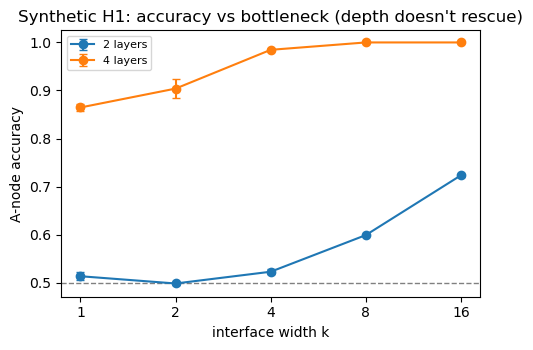

In [12]:
import matplotlib.pyplot as plt
SYN_KS = [1, 2, 4] if CONFIG["SMOKE"] else [1, 2, 4, 8, 16]
SYN_NG = 30 if CONFIG["SMOKE"] else 80
SYN_EP = 60 if CONFIG["SMOKE"] else 200
seeds = (0,) if CONFIG["SMOKE"] else tuple(CONFIG["SEEDS"])

syn = {d: {} for d in [2, 4]}
for depth in [2, 4]:
    for k in SYN_KS:
        ds = make_syn_dataset(k, n_graphs=SYN_NG); tr, te = split_list(ds, 0.7)
        syn[depth][k] = run_syn_seeds(tr, te, SYN_IN_DIM, seeds=seeds, kind="gin",
                                      layers=depth, epochs=SYN_EP, device=DEVICE)
        print(f"depth={depth} k={k} acc={syn[depth][k]['mean']:.3f}")

fig, ax = plt.subplots(figsize=(5, 3.6))
for depth in [2, 4]:
    m = [syn[depth][k]["mean"] for k in SYN_KS]; s = [syn[depth][k]["std"] for k in SYN_KS]
    ax.errorbar(SYN_KS, m, yerr=s, marker="o", capsize=3, label=f"{depth} layers")
ax.axhline(0.5, ls="--", c="gray", lw=1); ax.set_xscale("log", base=2); ax.set_xticks(SYN_KS)
ax.set_xticklabels(SYN_KS); ax.set_xlabel("interface width k"); ax.set_ylabel("A-node accuracy")
ax.set_title("Synthetic H1: accuracy vs bottleneck (depth doesn't rescue)"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(os.path.join(FIGS, "fig2_synthetic_H1.png"), dpi=150); plt.show()

## 6b. Synthetic mechanism — *why* accuracy falls: effective resistance ↑, Jacobian ↓

This is the **one-metric-threading-synthetic→real** panel: we measure the *same* two over-squashing diagnostics we apply to PINDER — **cross-interface effective resistance** and **Jacobian sensitivity** (∂ A-node output / ∂ marked-source input, averaged over freshly-initialised models, so it is an architecture property not a trained-ReLU artifact) — against the controllable bottleneck width `k`. The mechanism prediction: as `k` tightens, resistance rises and the Jacobian collapses, *quantitatively* explaining the accuracy drop above.

k= 1  eff_resistance=1.975  jacobian=2.942e-03  acc(4L)=0.865
k= 2  eff_resistance=1.196  jacobian=5.621e-03  acc(4L)=0.904
k= 4  eff_resistance=0.804  jacobian=8.843e-03  acc(4L)=0.985
k= 8  eff_resistance=0.540  jacobian=2.596e-02  acc(4L)=1.000
k=16  eff_resistance=0.456  jacobian=4.133e-02  acc(4L)=1.000


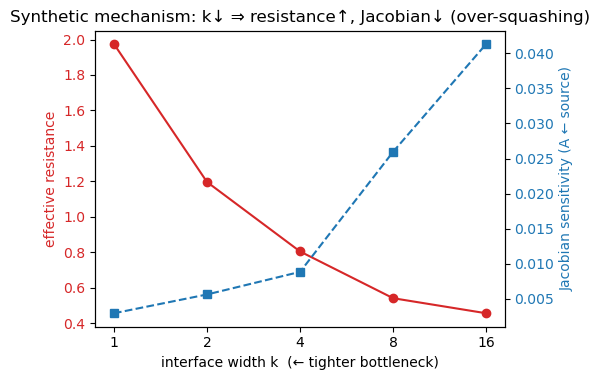

calibration: Spearman(resistance, accuracy)=-0.97, Spearman(Jacobian, accuracy)=+0.97 (resistance anti-correlates with accuracy; Jacobian correlates -- the same metric we carry to PINDER)


In [13]:
# For each k: mean effective resistance between the marked source (key in B) and the A-side
# read-out nodes, and the Jacobian sensitivity of A outputs to that source -- the two metrics
# that recur on real data. Averaged over fresh graphs/inits.
def syn_mechanism(k, n_graphs, layers=4, n_init=3):
    Rs, Js = [], []
    mk = lambda in_dim: MPNN(in_dim, 64, layers, "gin", out=2)   # same arch as the accuracy sweep
    for g in range(n_graphs):
        sd = 7000 + 137 * g
        G, a, b, _ = make_two_community(16, 16, 0.35, k, seed=sd)
        d = interface_source_task(G, a, b, seed=sd)
        key = d.key_b
        Rs.append(mean_pair_resistance(d.G, [(key, ai) for ai in a]))     # source -> A read-out
        Js.append(jacobian_sensitivity_init(mk, d, key, a, SYN_IN_DIM, n_init=n_init, device=DEVICE))
    return float(np.nanmean(Rs)), float(np.nanmean(Js))

SYN_NG_M = 8 if CONFIG["SMOKE"] else 20
res_curve, jac_curve = {}, {}
for k in SYN_KS:
    res_curve[k], jac_curve[k] = syn_mechanism(k, SYN_NG_M)
    print(f"k={k:2d}  eff_resistance={res_curve[k]:.3f}  jacobian={jac_curve[k]:.3e}  acc(4L)={syn[4][k]['mean']:.3f}")

# correlate the metric with accuracy across k (the calibration that licenses using it on real data)
import scipy.stats as _st
_ks = list(SYN_KS); _acc = [syn[4][k]["mean"] for k in _ks]
rho_RA, _ = _st.spearmanr([res_curve[k] for k in _ks], _acc)
rho_JA, _ = _st.spearmanr([jac_curve[k] for k in _ks], _acc)

fig, ax = plt.subplots(figsize=(5.6, 3.9))
ax.plot(SYN_KS, [res_curve[k] for k in SYN_KS], "o-", color="tab:red", label="eff. resistance (source→A)")
ax.set_xscale("log", base=2); ax.set_xticks(SYN_KS); ax.set_xticklabels(SYN_KS)
ax.set_xlabel("interface width k  (← tighter bottleneck)"); ax.set_ylabel("effective resistance", color="tab:red")
ax.tick_params(axis="y", labelcolor="tab:red")
ax2 = ax.twinx()
ax2.plot(SYN_KS, [jac_curve[k] for k in SYN_KS], "s--", color="tab:blue", label="Jacobian sensitivity")
ax2.set_ylabel("Jacobian sensitivity (A ← source)", color="tab:blue"); ax2.tick_params(axis="y", labelcolor="tab:blue")
ax.set_title("Synthetic mechanism: k↓ ⇒ resistance↑, Jacobian↓ (over-squashing)")
fig.tight_layout(); fig.savefig(os.path.join(FIGS, "fig2b_synthetic_mechanism.png"), dpi=150); plt.show()
print(f"calibration: Spearman(resistance, accuracy)={rho_RA:+.2f}, Spearman(Jacobian, accuracy)={rho_JA:+.2f} "
      "(resistance anti-correlates with accuracy; Jacobian correlates -- the same metric we carry to PINDER)")

## 7. Real pipeline: build & cache the dataset

Per system: fetch predicted monomers (+apo,+holo), build the two-monomer graph (`knn_bipartite` for the descriptor), transfer holo interface labels by sequence alignment, crop to the interface neighbourhood, compute descriptors (**cross-chain effective resistance**, curvature, spectral gap, interface size, **mean interface pLDDT**) and a **flexibility** proxy (predicted→holo Cα-RMSD). Cache to Drive. Every PINDER accessor is `# VERIFY`.

In [14]:
import biotite.structure as struc

def _af2_conf(ps):
    """Best-effort AF2-Multimer COMPLEX confidence (iptm, interface PAE) if PINDER exposes it on
    the system metadata. pLDDT is monomer confidence and is not meant to predict interface quality;
    ipTM/PAE are AF's actual complex signals, a fairer contest for H3. Most index builds do NOT ship
    these per-system, so this usually returns (nan, nan) and H3 falls back to pLDDT -- graceful."""
    try:
        md = getattr(ps, "metadata", None)
        if md is None:
            return float("nan"), float("nan")
        d = md.to_dict() if hasattr(md, "to_dict") else dict(md)
        iptm = next((float(d[k]) for k in d if "iptm" in str(k).lower()), float("nan"))
        pae  = next((float(d[k]) for k in d if "pae" in str(k).lower()), float("nan"))
        return iptm, pae
    except Exception:
        return float("nan"), float("nan")

def system_to_record(pid, cfg):
    ps = PinderSystem(pid)                                                 # VERIFY
    predR, predL = ps.pred_receptor, ps.pred_ligand                        # pose-free predicted monomers = model input
    if predR is None or predL is None:
        raise ValueError("no predicted monomer for one partner")          # skip cleanly (counted, not crash)
    predR = predR.atom_array; predL = predL.atom_array
    # LABELS come from the ground-truth BOUND pose. holo_receptor/holo_ligand are
    # origin-centered (centroid_dist=0); ps.native is the docked complex (chains R,L).
    nat = ps.native.atom_array                                             # VERIFY: bound complex
    holoR = nat[nat.chain_id == "R"]; holoL = nat[nat.chain_id == "L"]     # VERIFY chain ids R/L
    if holoR.array_length() == 0 or holoL.array_length() == 0:             # fallback to native_R/L
        holoR = ps.native_R.atom_array; holoL = ps.native_L.atom_array
    chR = np.unique(predR.chain_id)[0]; chL = np.unique(predL.chain_id)[0]
    monoA = load_monomer(predR, chR); monoB = load_monomer(predL, chL)

    # interface labels from holo (separate monomer arrays), aligned onto predicted residues
    labR, labL = interface_labels_two(holoR, holoL, cfg["INTERFACE_THRESH"])
    hRseq, hRid = chain_sequence(holoR); hLseq, hLid = chain_sequence(holoL)
    yA, mA = align_transfer_labels(monoA["res"], monoA["res_id"], hRseq, hRid, labR)
    yB, mB = align_transfer_labels(monoB["res"], monoB["res_id"], hLseq, hLid, labL)
    labels = np.concatenate([yA, yB]).astype(np.int64)

    # node features: ESM2 per-residue embeddings (pose-free) if loaded, else residue one-hot
    embA = esm_embed(monoA["res"], ESM) if ESM else None
    embB = esm_embed(monoB["res"], ESM) if ESM else None
    data, a, b, cross = build_two_monomer_graph(monoA, monoB, "knn_bipartite",
                                                knn_k=cfg["KNN"], edge_thresh=cfg["EDGE_THRESH"],
                                                embA=embA, embB=embB)
    data, a, b, labels = crop_two_monomer(data, a, b, labels, cross,
                                          crop_radius_hops=cfg["CROP_HOPS"], max_nodes=cfg["MAX_NODES"])
    if labels.sum() == 0 or len(a) == 0 or len(b) == 0:
        raise ValueError("degenerate (no interface / empty chain after crop)")

    G = nx.Graph(); G.add_nodes_from(range(data.n_real))
    for u, v in zip(*data.edge_index.numpy()):
        if u != v: G.add_edge(int(u), int(v))
    cross_in_crop = [(u, v) for u, v in zip(*data.edge_index.numpy())
                     if (u in set(a)) != (v in set(b))][:200]

    # flexibility: predicted->holo Cα-RMSD over SEQUENCE-ALIGNED residues (fixed).
    flex = aligned_ca_rmsd(monoA, holoR)

    # NATIVE interface bottleneck from the holo inter-chain contact graph (the first-iteration
    # H1/H3 metric). Kept as a CONTRAST -- the reviewer's point is the model never sees this geometry.
    ir = interface_resistance_holo(holoR, holoL, contact=10.0)
    # MODELLED interface bottleneck (EXP1, the key fix): effective resistance on the model's OWN
    # pose-free input graph between true-interface residues of A and B -- what the model must route
    # through. This is the metric H1/H3 should track, and is computed on the cropped graph.
    model_ir = model_interface_resistance(data, a, b, labels)
    iptm, pae_iface = _af2_conf(ps)   # best-effort AF2-MM complex confidence (usually nan)

    nf = neff_map.get(str(pid), float("nan"))
    prev = float(labels.mean())
    # Skip degenerate systems: overlapping holo coords (homodimer symmetry copies)
    # give prevalence ~1; failed sequence alignment gives ~0. Either is unusable.
    cdist = float(np.linalg.norm(holoR.coord.mean(0) - holoL.coord.mean(0)))
    if prev > 0.6 or prev < 0.02:
        raise ValueError(f"degenerate interface prevalence={prev:.2f} (holo centroid dist={cdist:.1f}A)")
    return {"id": str(pid), "graph": data, "labels": labels,
            "iface_reff": ir["iface_reff"], "n_contacts": ir["n_contacts"],
            "model_iface_reff": model_ir,                       # EXP1: modelled-graph bottleneck (primary)
            "cross_reff": cross_chain_resistance(data, a, b),   # input-graph (for reference)
            "iptm": iptm, "pae_iface": pae_iface,               # best-effort AF2-MM complex confidence
            "mean_curv": mean_curvature(G, cross_in_crop) if cross_in_crop else float("nan"),
            "spectral_gap": spectral_gap(G),
            "iface_size": int(labels.sum()), "n_nodes": int(data.n_real), "prevalence": prev,
            "mean_plddt": float(np.concatenate([monoA["plddt"], monoB["plddt"]]).mean()),
            "neff": nf, "log_neff": float(np.log1p(nf)) if np.isfinite(nf) else float("nan"),
            "flex_rmsd": flex, "mismatch": int(mA + mB),
            "_diag": {"holoR_chains": list(np.unique(holoR.chain_id)),
                      "holoL_chains": list(np.unique(holoL.chain_id)),
                      "predR_n": int(len(monoA["res"])), "predL_n": int(len(monoB["res"])),
                      "holo_centroid_dist": cdist}}

def build_split(ids, cfg, tag):
    # v9: store BOTH one-hot AND ESM per residue (for the feature-richness sweep) => re-parse.
    path = os.path.join(CACHE, f"pinder_{tag}_v9{'_smoke' if cfg['SMOKE'] else ''}.pt")
    if os.path.exists(path):
        recs = torch.load(path, weights_only=False)
        if len(recs) >= 0.3 * len(ids):       # guard against a stale/short cache
            print(f"load {path} ({len(recs)} records)"); return recs
        print(f"!! cached {path} has {len(recs)} records for {len(ids)} ids -- stale, rebuilding")
    # checkpoint + resume: a 400-system run survives a Colab disconnect.
    part = path + ".part"
    recs, done = [], set()
    if os.path.exists(part):
        recs = torch.load(part, weights_only=False); done = {r["id"] for r in recs}
        print(f"resuming {tag}: {len(recs)} already parsed")
    for i, pid in enumerate(ids):
        if str(pid) in done:
            continue
        try:
            recs.append(system_to_record(pid, cfg))
        except Exception as e:
            print(f"  [skip {pid}] {type(e).__name__}: {e}")
        if (i + 1) % 25 == 0:
            torch.save(recs, part); print(f"  {i+1}/{len(ids)} ({len(recs)} kept, checkpointed)")
    torch.save(recs, path)
    if os.path.exists(part):
        os.remove(part)
    print("saved", len(recs), "to", path)
    return recs

# The cache stores the FULL feature set [onehot, esm, plddt, degree, chain]; *_full keeps it for the
# feature-richness sweep. _regime(mode) projects to a regime AND rebuilds its kNN cross layer from
# that regime's OWN features (self-consistent: onehot->onehot-kNN, esm->esm-kNN) -- so the weak end
# reproduces v7's clean H2 and the rich end reproduces v8. model_iface_reff is recomputed on the
# regime graph for the MAIN run (the H1 metric must match the graph the model actually uses).
train_recs_full = build_split(subset["train"], CONFIG, "train")
test_recs_full  = build_split(subset["test"],  CONFIG, "test")
def _regime(recs, mode, recompute_reff=False):
    out = []
    for r in recs:
        g = rebuild_cross_knn(select_features(r["graph"], mode), CONFIG["KNN"])
        rr = {**r, "graph": g}
        if recompute_reff:
            ch = g.x[:, -1].numpy()
            rr["model_iface_reff"] = model_interface_resistance(
                g, np.where(ch == 0)[0].tolist(), np.where(ch == 1)[0].tolist(), r["labels"])
        out.append(rr)
    return out
train_recs = _regime(train_recs_full, CONFIG["MAIN_FEATURES"], recompute_reff=True)
test_recs  = _regime(test_recs_full,  CONFIG["MAIN_FEATURES"], recompute_reff=True)
def _prev(recs):
    fr = [float(r["labels"].mean()) for r in recs if len(r["labels"])]
    return (np.mean(fr), np.mean([r["graph"].x.size(0) for r in recs]))
pv, sz = _prev(train_recs)
print("train", len(train_recs), "test", len(test_recs),
      f"| MAIN_FEATURES='{CONFIG['MAIN_FEATURES']}' -> in_dim", train_recs[0]["graph"].x.size(1),
      f"(cache stores esm_dim={getattr(train_recs_full[0]['graph'],'esm_dim','?')})",
      f"| mean interface prevalence={pv:.2f} (want <~0.5, not ~1)",
      f"| mean nodes={sz:.0f}")
# DIAGNOSTIC: reveal what the holo arrays actually contain (root-causes the ~0.9
# prevalence) and whether the real interface resistance varies across systems.
print("\n-- per-system diagnostics (first 3 test) --")
for r in test_recs[:3]:
    d = r["_diag"]
    print(f"  {r['id']}: holo_centroid_dist={d['holo_centroid_dist']:.1f}A "
          f"predR/L_n={d['predR_n']}/{d['predL_n']} | prevalence={r['prevalence']:.2f} "
          f"iface_reff(native)={r['iface_reff']:.3f} model_iface_reff={r['model_iface_reff']:.3f} "
          f"contacts={r['n_contacts']} (centroid_dist<~5A => overlapping holo coords = bad)")
for key in ("iface_reff", "model_iface_reff"):
    vals = [r[key] for r in test_recs if np.isfinite(r[key])]
    if vals:
        print(f"  {key} across test: n={len(vals)} range {min(vals):.3f}..{max(vals):.3f} "
              f"std={np.std(vals):.3f}  (want real spread, not ~constant)")
    else:
        print(f"  !! {key} all non-finite")

load /home/jovyan/grl_miniproject/grl_cache/pinder_train_v9.pt (383 records)
load /home/jovyan/grl_miniproject/grl_cache/pinder_test_v9.pt (243 records)
train 383 test 243 | MAIN_FEATURES='onehot' -> in_dim 24 (cache stores esm_dim=480) | mean interface prevalence=0.16 (want <~0.5, not ~1) | mean nodes=611

-- per-system diagnostics (first 3 test) --
  7zry__A1_O60341--7zry__B1_Q9UKL0: holo_centroid_dist=67.6A predR/L_n=852/485 | prevalence=0.15 iface_reff(native)=0.145 model_iface_reff=0.228 contacts=302 (centroid_dist<~5A => overlapping holo coords = bad)
  5vpb__B1_P17535--5vpb__A1_P53539: holo_centroid_dist=8.5A predR/L_n=347/338 | prevalence=0.16 iface_reff(native)=0.147 model_iface_reff=0.252 contacts=180 (centroid_dist<~5A => overlapping holo coords = bad)
  8h62__A1_P0DJM0--8h62__B1_P12830: holo_centroid_dist=28.0A predR/L_n=800/882 | prevalence=0.09 iface_reff(native)=0.162 model_iface_reff=0.199 contacts=122 (centroid_dist<~5A => overlapping holo coords = bad)
  iface_reff ac

## 8. Real models: interface predictor + rewiring

Node classifier (interface vs not) with a class-weighted loss. Metrics: **F1 / AUPRC** (primary; class-imbalanced), AUROC, **ECE** calibration. Train per rewiring variant × 3 seeds.

In [15]:
def train_interface_model(train_recs, test_recs, in_dim, kind="gin", layers=4, hid=64,
                          epochs=120, lr=2e-3, fa_last=False, seed=0, device="cpu",
                          pos_weight_cap=3.0, fa_max=900):
    """Node classifier: interface residue vs not. Class-weighted CE. Returns metrics.

    Stability fixes (the 4-layer GIN previously collapsed to a constant output on the large
    sparse PINDER graphs): LayerNorm + hidden residuals (norm/residual=True), a *capped*
    positive class weight (the raw neg/pos ~5x drove the degenerate all-constant optimum),
    a gentler lr (5e-3 -> 2e-3) and a touch of weight decay."""
    from sklearn.metrics import f1_score, average_precision_score, roc_auc_score
    set_seed(seed)
    model = MPNN(in_dim, hid, layers, kind, out=2, fa_last=fa_last,
                 norm=True, residual=True, fa_max=fa_max).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    # global class weight from train, capped so aggressive weighting can't induce collapse
    pos = sum(int((r["labels"] == 1).sum()) for r in train_recs)
    neg = sum(int((r["labels"] == 0).sum()) for r in train_recs)
    w = torch.tensor([1.0, min(max(neg, 1) / max(pos, 1), pos_weight_cap)],
                     dtype=torch.float, device=device)
    for ep in range(epochs):
        model.train()
        for r in np.random.permutation(len(train_recs)):
            r = train_recs[r]; d = r["graph"]
            y = torch.tensor(r["labels"], dtype=torch.long, device=device)
            real = torch.zeros(d.x.size(0), dtype=torch.bool, device=device); real[:len(y)] = True
            yy = torch.zeros(d.x.size(0), dtype=torch.long, device=device); yy[:len(y)] = y
            opt.zero_grad()
            out = model(d.x.to(device), d.edge_index.to(device))
            F.cross_entropy(out[real], yy[real], weight=w).backward(); opt.step()
    # eval (pooled over test systems)
    model.eval(); ys = []; ps = []
    per_system = []
    with torch.no_grad():
        for r in test_recs:
            d = r["graph"]; y = r["labels"]
            prob = F.softmax(model(d.x.to(device), d.edge_index.to(device)), 1)[:, 1].cpu().numpy()
            prob = prob[:len(y)]
            ys.append(y); ps.append(prob)
            if len(np.unique(y)) > 1:
                per_system.append({"f1": f1_score(y, prob > 0.5),
                                   "auprc": average_precision_score(y, prob)})
    Y = np.concatenate(ys); P = np.concatenate(ps)
    # best-threshold F1 (the 0.5 threshold can be miscalibrated on imbalanced data)
    ths = np.linspace(0.1, 0.9, 17)
    f1_best = max(float(f1_score(Y, P > t)) for t in ths) if len(np.unique(Y)) > 1 else 0.0
    out = {"f1": float(f1_score(Y, P > 0.5)), "f1_best": f1_best,
           "auprc": float(average_precision_score(Y, P)),
           "auroc": float(roc_auc_score(Y, P)) if len(np.unique(Y)) > 1 else float("nan"),
           "ece": float(_ece(P, Y)),
           "per_system": per_system}
    return out, model

def _ece(prob, y, n_bins=10):
    conf = np.where(prob >= 0.5, prob, 1 - prob)
    pred = (prob >= 0.5).astype(int); correct = (pred == y).astype(float)
    bins = np.linspace(0, 1, n_bins + 1); e = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum():
            e += abs(correct[m].mean() - conf[m].mean()) * m.mean()
    return e

In [16]:
def add_rewiring(recs, rewiring, knn_k=None):
    """Re-derive each cached (knn_bipartite) cropped graph under a different cross-chain edge
    layer; labels unchanged. The chain indicator is the last feature column, so cross edges =
    edges between differing-chain nodes. `sdrf` adds curvature-targeted supporting edges and stashes
    the count (`_n_add`) so we can show it relieves the bottleneck with FAR fewer edges than fa/virtual."""
    out = []
    for r in recs:
        d = r["graph"]
        if rewiring in ("knn_bipartite", "fa"):
            out.append(r); continue
        chain = d.x[:, -1].numpy()
        ei = d.edge_index.numpy()
        if rewiring == "none":                       # drop the cross layer (max bottleneck)
            keep = [(u, v) for u, v in zip(ei[0], ei[1]) if chain[u] == chain[v]]
            kk = torch.tensor(np.array(keep).T, dtype=torch.long) if keep else torch.zeros((2, 0), dtype=torch.long)
            nd = Data(x=d.x, edge_index=kk); nd.n_real = d.n_real
            if hasattr(d, "sim_dim"): nd.sim_dim = d.sim_dim
            out.append({**r, "graph": nd})
        elif rewiring == "virtual":                  # add a hub node tied to every residue
            n = d.x.size(0)
            extra = np.array([[n]*n + list(range(n)), list(range(n)) + [n]*n])
            nd = Data(x=torch.cat([d.x, torch.zeros(1, d.x.size(1))], 0),
                      edge_index=torch.tensor(np.concatenate([ei, extra], 1), dtype=torch.long))
            nd.n_real = d.n_real
            out.append({**r, "graph": nd})
        elif rewiring == "sdrf":                      # curvature-targeted (Topping et al.) -- few edges
            a_idx = [i for i in range(d.x.size(0)) if chain[i] == 0]
            b_idx = [i for i in range(d.x.size(0)) if chain[i] == 1]
            nd, n_add = sdrf_rewire(d, a_idx, b_idx)
            out.append({**r, "graph": nd, "_n_add": n_add})
        else:
            out.append(r)
    return out

# Parsing is done -> the ESM model is no longer needed (features are cached). Free it from the GPU
# so the 8 GB session has headroom for training (esp. the fa complete-graph layer).
if ESM is not None and DEVICE == "cuda":
    try:
        ESM["model"] = ESM["model"].to("cpu"); torch.cuda.empty_cache()
        print("freed ESM model from GPU (features cached; not needed for training)")
    except Exception as _e:
        print("ESM free note:", _e)

in_dim = train_recs[0]["graph"].x.size(1)
real_results = {}; jac_models = {}; jac_test = {}   # keep seed-0 models + their test recs for EXP3
SEEDS_MAIN = CONFIG["SEEDS"][:N_SEEDS_MAIN]
for rw in CONFIG["REWIRINGS"]:
    fa = (rw == "fa")
    tr = add_rewiring(train_recs, rw, CONFIG["KNN"]); te = add_rewiring(test_recs, rw, CONFIG["KNN"])
    accs = []
    for s in SEEDS_MAIN:
        m, mdl = train_interface_model(tr, te, in_dim, kind="gin", layers=CONFIG["LAYERS"],
                                       hid=CONFIG["HID"], epochs=CONFIG["EPOCHS"], fa_last=fa,
                                       seed=s, device=DEVICE, fa_max=CONFIG["FA_MAX_NODES"])
        accs.append(m)
        if s == SEEDS_MAIN[0]:
            jac_models[rw] = mdl.to("cpu"); jac_test[rw] = te   # stash on CPU (freed for next rewiring)
        else:
            del mdl
        if DEVICE == "cuda": torch.cuda.empty_cache()
    agg = {k: float(np.mean([a[k] for a in accs])) for k in ["f1","f1_best","auprc","auroc","ece"]}
    agg["auprc_std"] = float(np.std([a["auprc"] for a in accs]))
    agg["n_add"] = float(np.mean([rr.get("_n_add", 0) for rr in te])) if rw == "sdrf" else float("nan")
    real_results[rw] = agg
    _extra = f" | +{agg['n_add']:.0f} curv-edges" if rw == "sdrf" else ""
    print(f"{rw:14s} AUPRC={agg['auprc']:.3f}±{agg['auprc_std']:.3f} F1best={agg['f1_best']:.3f} "
          f"AUROC={agg['auroc']:.3f} ECE={agg['ece']:.3f}{_extra}")

import pandas as pd
tbl = pd.DataFrame(real_results).T[["auprc","auprc_std","f1_best","auroc","ece"]]
tbl.to_csv(os.path.join(RESULTS, "real_model_table.csv")); display(tbl)
if not np.isnan(real_results["sdrf"]["n_add"]):
    print(f">>> SDRF adds only ~{real_results['sdrf']['n_add']:.0f} curvature-targeted edges/system "
          f"(vs fa's complete final layer / virtual's N-edge hub) for a comparable gain.")

freed ESM model from GPU (features cached; not needed for training)
none           AUPRC=0.194±0.004 F1best=0.292 AUROC=0.528 ECE=0.084
virtual        AUPRC=0.233±0.004 F1best=0.325 AUROC=0.589 ECE=0.038
knn_bipartite  AUPRC=0.232±0.005 F1best=0.325 AUROC=0.589 ECE=0.039
fa             AUPRC=0.224±0.006 F1best=0.312 AUROC=0.566 ECE=0.048
sdrf           AUPRC=0.230±0.007 F1best=0.322 AUROC=0.584 ECE=0.040 | +48 curv-edges


,auprc,auprc_std,f1_best,auroc,ece
none,0.194078,0.004100,0.292347,0.527988,0.084402
virtual,0.232853,0.004034,0.324607,0.588694,0.038128
knn_bipartite,0.231799,0.004656,0.325318,0.588699,0.038615
fa,0.223895,0.006145,0.311753,0.566299,0.048283
sdrf,0.229506,0.007216,0.322207,0.584480,0.040297


>>> SDRF adds only ~48 curvature-targeted edges/system (vs fa's complete final layer / virtual's N-edge hub) for a comparable gain.


## 9. Analyses & figures — H1, H2, H3, H4, H5

**Key fix (the reviewer's #1):** H1/H3 now correlate per-system skill against the **modelled-graph** interface resistance (`model_iface_reff` — the pose-free bottleneck the model actually routes through), with the **native** holo resistance kept only as a *contrast*. `fig3` shows modelled-vs-native side by side. Every reported ρ gets a **bootstrap CI** and a **pre-registered one-sided** p (we predicted the sign), plus a **minimum-detectable-effect** note for the underpowered n. H2: rewiring deltas (5 knobs incl. SDRF) with seed error bars. H3: partial bars vs pLDDT / Neff / flexibility (and ipTM/PAE if PINDER ships them). H5: train↔test skill by modelled-bottleneck tertile. Verdicts are computed from the statistics, not hand-set.

In [17]:
def spearman(x, y):
    from scipy.stats import spearmanr
    return spearmanr(x, y, nan_policy="omit")

def partial_spearman(df, x, y, control):
    """Spearman partial correlation of x,y controlling for `control`.
    If `control` has ~no variance, falls back to the plain Spearman(x,y)."""
    from scipy.stats import rankdata, spearmanr
    def resid(a, b):
        a = rankdata(a); b = rankdata(b)
        if np.std(b) < 1e-9:
            return a - a.mean()
        return a - np.polyval(np.polyfit(b, a, 1), b)
    sub = df[[x, y, control]].replace([np.inf, -np.inf], np.nan).dropna()
    if len(sub) < 5:
        return float("nan"), float("nan")
    rx = resid(sub[x].values, sub[control].values)
    ry = resid(sub[y].values, sub[control].values)
    rho, p = spearmanr(rx, ry)
    return float(rho), float(p)

def bootstrap_ci_spearman(x, y, n_boot=2000, alpha=0.05, seed=0):
    """Percentile bootstrap CI for Spearman rho (resample systems). Reporting the CI rather
    than a bare p makes the weak, underpowered H1/H3 correlations honest. Returns (rho, lo, hi)."""
    from scipy.stats import spearmanr
    x = np.asarray(x, float); y = np.asarray(y, float)
    m = np.isfinite(x) & np.isfinite(y); x, y = x[m], y[m]
    n = len(x)
    if n < 5:
        return float("nan"), float("nan"), float("nan")
    rho = float(spearmanr(x, y)[0])
    rng = np.random.default_rng(seed); boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        if np.std(x[idx]) < 1e-12 or np.std(y[idx]) < 1e-12:
            continue
        boots.append(spearmanr(x[idx], y[idx])[0])
    if not boots:
        return rho, float("nan"), float("nan")
    lo, hi = np.nanpercentile(boots, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return rho, float(lo), float(hi)

def spearman_one_sided(x, y, direction="neg"):
    """Pre-registered ONE-SIDED Spearman p-value (we predict the sign a priori, so the one-sided
    test is the correct, more powerful test). Returns (rho, p_one_sided)."""
    from scipy.stats import spearmanr
    rho, p_two = spearmanr(x, y, nan_policy="omit")
    rho = float(rho)
    if not np.isfinite(rho):
        return float("nan"), float("nan")
    in_dir = (direction == "neg" and rho < 0) or (direction == "pos" and rho > 0)
    return rho, float(p_two / 2 if in_dir else 1 - p_two / 2)

def min_detectable_rho(n, alpha=0.05, power=0.8, one_sided=True):
    """Approx. minimum |rho| detectable at this n/alpha/power (Fisher-z). Quantifies the
    'we are underpowered at n=243' caveat instead of just reporting p=0.17."""
    from scipy.stats import norm
    if n is None or n < 4:
        return float("nan")
    z_a = norm.ppf(1 - (alpha if one_sided else alpha / 2))
    z_b = norm.ppf(power)
    return float(np.tanh((z_a + z_b) / np.sqrt(n - 3)))

>>> per-system model='knn_bipartite' x10 seeds | pooled AUROC=0.589 | INTERPRETABLE
per-system rows: 243 | seed-avg mean AUROC=0.548 mean skill(AUPRC-base)=+0.044
H1 MODELLED-bottleneck rho=-0.490 (1-sided p=2.1e-16; 95%CI [-0.59,-0.39]; n=243) | per-seed [-0.343, -0.286, -0.443, -0.295, -0.288, -0.381, -0.388, -0.43, -0.274, -0.44] sign-stable=True
   NATIVE-bottleneck CONTRAST rho=-0.114 (p=0.075) | relieved[virtual] rho=-0.386 (p=4.8e-10)
   MDE |rho|>=0.159 at n=243 (alpha=.05,power=.8,1-sided) -> H1 SUPPORTED


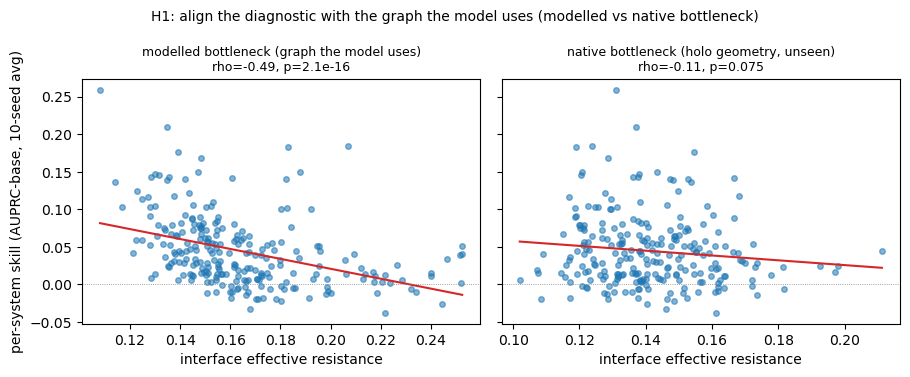

H2 AUPRC deltas vs none: {'none': 0.0, 'virtual': 0.039, 'knn_bipartite': 0.038, 'fa': 0.03, 'sdrf': 0.035} -> SUPPORTED (all cross-chain rewirings > none)


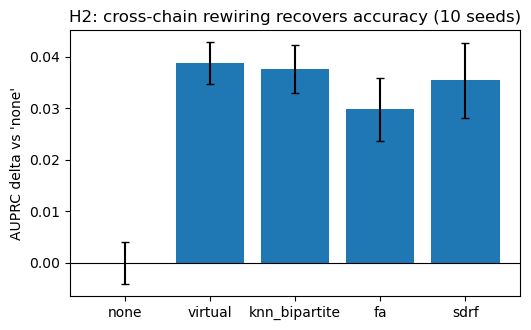

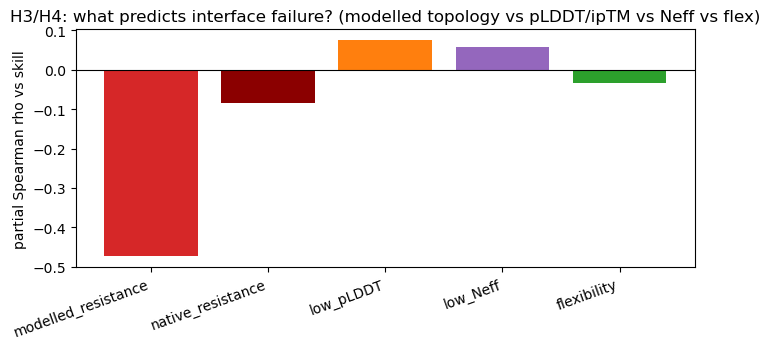

H3 partial-rho (p): {'modelled_resistance': '-0.473 (p=5.6e-15)', 'native_resistance': '-0.085 (p=0.18)', 'low_pLDDT': '+0.075 (p=0.25)', 'low_Neff': '+0.058 (p=0.37)', 'flexibility': '-0.034 (p=0.59)'}
   H3 headline SUPPORTED: rho(modelled_res)=-0.473 (p=5.6e-15) vs strongest-confidence |rho|=0.075 (AF2 ipTM/PAE available=False)
H5 skill by MODELLED-resistance tertile (low->high): {'train': {0: 0.291, 1: 0.299, 2: 0.334}, 'test': {0: 0.073, 1: 0.035, 2: 0.025}} -> monotone=True, SUPPORTED


In [18]:
import matplotlib.pyplot as plt, pandas as pd

RES = "model_iface_reff"   # EXP1: MODELLED-graph bottleneck (what the model routes through) -- PRIMARY
RES_NAT = "iface_reff"     # native holo bottleneck -- first-iteration metric, kept only as a CONTRAST
ACC = "skill"              # base-rate-free per-system outcome (AUPRC - prevalence)
KEEP = ["model_iface_reff","iface_reff","cross_reff","mean_plddt","flex_rmsd","iface_size",
        "n_nodes","neff","log_neff","prevalence","n_contacts","iptm","pae_iface"]

def per_system_f1(model, recs):
    from sklearn.metrics import f1_score, average_precision_score, roc_auc_score
    model.eval(); rows = []
    with torch.no_grad():
        for r in recs:
            d = r["graph"]; y = r["labels"]
            p = torch.softmax(model(d.x.to(DEVICE), d.edge_index.to(DEVICE)), 1)[:, 1].cpu().numpy()[:len(y)]
            if len(np.unique(y)) < 2: continue
            base = float(np.mean(y))                      # base rate = interface prevalence
            ap = float(average_precision_score(y, p))
            rows.append({**{k: r.get(k, float("nan")) for k in ["id"] + KEEP},
                         "f1": float(f1_score(y, p > 0.5)), "auprc_sys": ap,
                         "auroc_sys": float(roc_auc_score(y, p)),
                         "skill": ap - base})           # AUPRC above base rate (base-rate-free)
    return pd.DataFrame(rows)

def per_system_multiseed(rw, seeds, rho_col=RES):
    """Train one interface predictor per seed and AVERAGE per-system metrics (denoises the noisy,
    small-interface skill outcome so H1/H3 don't ride on one initialisation). Returns averaged
    TEST df, averaged TRAIN df, mean pooled test AUROC, and the per-seed rho list vs ``rho_col``
    (so we report sign-stability, not one p)."""
    te_rw = add_rewiring(test_recs, rw, CONFIG["KNN"]); tr_rw = add_rewiring(train_recs, rw, CONFIG["KNN"])
    te_dfs, tr_dfs, pooled = [], [], []
    for s in seeds:
        m, mdl = train_interface_model(tr_rw, te_rw, in_dim, kind="gin", layers=CONFIG["LAYERS"],
                                       hid=CONFIG["HID"], epochs=CONFIG["EPOCHS"],
                                       fa_last=(rw == "fa"), seed=s, device=DEVICE)
        te_dfs.append(per_system_f1(mdl, te_rw).set_index("id"))
        tr_dfs.append(per_system_f1(mdl, tr_rw).set_index("id")); pooled.append(m["auroc"])
    NUM = ["f1", "auprc_sys", "auroc_sys", "skill"]
    def _avg(dfs):
        idx = dfs[0].index; out = dfs[0][KEEP].copy()
        for c in NUM: out[c] = np.mean([d.loc[idx, c].values for d in dfs], axis=0)
        return out.reset_index()
    rhos = [float(spearman(d[rho_col], d["skill"])[0]) for d in te_dfs]
    return _avg(te_dfs), _avg(tr_dfs), float(np.mean(pooled)), rhos

# Per-system model for H1/H3/H5: FIXED a priori to 'knn_bipartite' (pose-free cross edges present;
# not auto-picked -> no selection bias). 'virtual' (a global hub that routes AROUND the neck) is the
# bottleneck-RELIEVED robustness check. Skill is averaged over all seeds; we report the per-seed rho.
H1_RW = "knn_bipartite"
SEEDS_PS = CONFIG["SEEDS"][:N_SEEDS_MAIN]
df, df_tr, auroc_main, rhos_main = per_system_multiseed(H1_RW, SEEDS_PS, rho_col=RES)
df.to_csv(os.path.join(RESULTS, "per_system.csv"), index=False)
H1H3_OK = auroc_main > 0.52
print(f">>> per-system model='{H1_RW}' x{len(SEEDS_PS)} seeds | pooled AUROC={auroc_main:.3f} "
      f"| {'INTERPRETABLE' if H1H3_OK else 'AT CHANCE -> treat H1/H3/H5 as NULL'}")
print("per-system rows:", len(df), "| seed-avg mean AUROC=%.3f mean skill(AUPRC-base)=%+.3f"
      % (df["auroc_sys"].mean(), df["skill"].mean()))
if not H1H3_OK:
    print("!! WARNING: predictor at chance; H1/H3/H5 below are NOT interpretable (HANDOFF Option B).")

# --- H1: MODELLED bottleneck (primary, the reviewer's fix) vs NATIVE bottleneck (contrast) ---
rho_mod, p_mod_two = spearman(df[RES], df[ACC])
_, p_mod = spearman_one_sided(df[RES], df[ACC], "neg")        # pre-registered one-sided (we predict <0)
rho_mod_b, mod_lo, mod_hi = bootstrap_ci_spearman(df[RES], df[ACC])
rho_nat, p_nat = spearman(df[RES_NAT], df[ACC])
MDE = min_detectable_rho(len(df))                            # |rho| we could detect at this n
df_rel, _, auroc_rel, rhos_rel = per_system_multiseed("virtual", SEEDS_PS, rho_col=RES)  # relieved
rho_mod_rel, p_mod_rel = spearman(df_rel[RES], df_rel[ACC])
H1_STABLE = bool(len(rhos_main) > 1 and all(r < 0 for r in rhos_main))
H1_SUPPORTED = bool(rho_mod < 0 and p_mod < 0.05)            # one-sided, pre-registered sign
print(f"H1 MODELLED-bottleneck rho={rho_mod:+.3f} (1-sided p={p_mod:.2g}; 95%CI [{mod_lo:+.2f},{mod_hi:+.2f}]; n={len(df)}) "
      f"| per-seed {[round(r,3) for r in rhos_main]} sign-stable={H1_STABLE}")
print(f"   NATIVE-bottleneck CONTRAST rho={rho_nat:+.3f} (p={p_nat:.2g}) | relieved[virtual] rho={rho_mod_rel:+.3f} (p={p_mod_rel:.2g})")
print(f"   MDE |rho|>={MDE:.3f} at n={len(df)} (alpha=.05,power=.8,1-sided) -> H1 {'SUPPORTED' if H1_SUPPORTED else 'NOT supported'}")

# fig3: align the diagnostic with the graph the model uses -- modelled (left) vs native (right).
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.8), sharey=True)
for ax, (col, ttl, rr, pp) in zip(axes,
        [(RES, "modelled bottleneck (graph the model uses)", rho_mod, p_mod),
         (RES_NAT, "native bottleneck (holo geometry, unseen)", rho_nat, p_nat)]):
    sub = df[[col, ACC]].replace([np.inf,-np.inf], np.nan).dropna()
    ax.scatter(sub[col], sub[ACC], s=16, alpha=0.55)
    if len(sub) > 2:
        xx = np.linspace(sub[col].min(), sub[col].max(), 50)
        ax.plot(xx, np.polyval(np.polyfit(sub[col], sub[ACC], 1), xx), c="tab:red", lw=1.5)
    ax.axhline(0, c="gray", lw=0.6, ls=":")
    ax.set_title(f"{ttl}\nrho={rr:+.2f}, p={pp:.2g}", fontsize=9)
    ax.set_xlabel("interface effective resistance")
axes[0].set_ylabel(f"per-system skill (AUPRC-base, {len(SEEDS_PS)}-seed avg)")
fig.suptitle("H1: align the diagnostic with the graph the model uses (modelled vs native bottleneck)", fontsize=10)
fig.tight_layout(); fig.savefig(os.path.join(FIGS, "fig3_real_H1.png"), dpi=150); plt.show()

# --- H2: rewiring deltas vs 'none' (AUPRC, seed error bars). knn/fa/sdrf add cross edges WITHOUT a
# global hub, so their deltas>0 isolate bottleneck relief (not the virtual node's extra capacity). ---
base = real_results["none"]["auprc"]
rws = CONFIG["REWIRINGS"]; vals = [real_results[r]["auprc"] - base for r in rws]
errs = [real_results[r]["auprc_std"] for r in rws]
H2_SUPPORTED = bool(all(real_results[r]["auprc"] - base > 0 for r in rws if r != "none"))
print(f"H2 AUPRC deltas vs none: {dict(zip(rws, [round(v,3) for v in vals]))} "
      f"-> {'SUPPORTED' if H2_SUPPORTED else 'NOT supported'} (all cross-chain rewirings > none)")
fig, ax = plt.subplots(figsize=(5.4, 3.4))
ax.bar(rws, vals, yerr=errs, capsize=3, color=["gray"]+["tab:blue"]*(len(rws)-1)); ax.axhline(0, c="k", lw=0.8)
ax.set_ylabel("AUPRC delta vs 'none'"); ax.set_title(f"H2: cross-chain rewiring recovers accuracy ({len(SEEDS_PS)} seeds)")
fig.tight_layout(); fig.savefig(os.path.join(FIGS, "fig4_real_H2.png"), dpi=150); plt.show()

# --- H3 (headline) + H4: partial Spearman of skill vs each predictor (control = the other terms).
# Oriented so a POSITIVE bar = "more of this => worse skill". The topology term is now the MODELLED
# resistance (the metric the model uses); native is shown alongside. ipTM/PAE added only if present. ---
df_h3 = df.copy().assign(acc=df[ACC])
df_h3["neg_plddt"] = -df_h3["mean_plddt"]; df_h3["neg_neff"] = -df_h3["neff"]
terms = {"modelled_resistance": (RES, "mean_plddt"),
         "native_resistance": (RES_NAT, "mean_plddt"),
         "low_pLDDT": ("neg_plddt", RES),
         "low_Neff": ("neg_neff", RES),
         "flexibility": ("flex_rmsd", RES)}
# AF's REAL complex-confidence signals (fairer than monomer pLDDT) -- only if PINDER shipped them.
for nm, col, sgn in [("low_ipTM", "iptm", -1.0), ("high_PAE", "pae_iface", +1.0)]:
    if col in df_h3 and df_h3[col].replace([np.inf,-np.inf], np.nan).notna().sum() >= 5:
        df_h3["t_" + col] = sgn * df_h3[col]; terms[nm] = ("t_" + col, RES)
AF2_CONF_AVAIL = any(k in terms for k in ("low_ipTM", "high_PAE"))
bars, bars_p = {}, {}
for name, (xcol, ctrl) in terms.items():
    if xcol in df_h3 and df_h3[xcol].replace([np.inf, -np.inf], np.nan).notna().sum() >= 5:
        bars[name], bars_p[name] = partial_spearman(df_h3, xcol, "acc", ctrl)
ir_rho = bars.get("modelled_resistance", float("nan")); ir_p = bars_p.get("modelled_resistance", 1.0)
pl_rho = bars.get("low_pLDDT", float("nan"))
conf_rho = max([abs(bars.get(k, 0.0)) for k in ("low_pLDDT","low_ipTM","high_PAE")] + [0.0])  # strongest confidence term
H3_DIRECTIONAL = bool(ir_rho < 0 and abs(ir_rho) > conf_rho)   # modelled bottleneck out-predicts confidence
H3_SIGNIFICANT = bool(ir_p < 0.05)
H3_SUPPORTED = bool(H3_DIRECTIONAL and H3_SIGNIFICANT)
fig, ax = plt.subplots(figsize=(7.2, 3.6))
ax.bar(range(len(bars)), list(bars.values()),
       color=["tab:red","darkred","tab:orange","tab:purple","tab:green","tab:brown","tab:pink"][:len(bars)])
ax.axhline(0, c="k", lw=0.8)
ax.set_xticks(range(len(bars))); ax.set_xticklabels(list(bars.keys()), rotation=20, ha="right")
ax.set_ylabel("partial Spearman rho vs skill")
ax.set_title("H3/H4: what predicts interface failure? (modelled topology vs pLDDT/ipTM vs Neff vs flex)")
fig.tight_layout(); fig.savefig(os.path.join(FIGS, "fig5_real_H3.png"), dpi=150); plt.show()
print("H3 partial-rho (p):", {k: f"{v:+.3f} (p={bars_p[k]:.2g})" for k, v in bars.items()})
_h3verdict = ("SUPPORTED" if H3_SUPPORTED else
              "DIRECTIONAL only (modelled bottleneck leads confidence & right sign, but p>=0.05)" if H3_DIRECTIONAL else
              "NOT supported")
print(f"   H3 headline {_h3verdict}: rho(modelled_res)={ir_rho:+.3f} (p={ir_p:.2g}) "
      f"vs strongest-confidence |rho|={conf_rho:.3f} (AF2 ipTM/PAE available={AF2_CONF_AVAIL})")

# --- H5: de-leaked generalization gap vs MODELLED bottleneck tightness (train vs test by tertile) ---
def tertile_skill(d, col=RES):
    d = d.replace([np.inf, -np.inf], np.nan).dropna(subset=[col]).copy()
    if len(d) < 3: return {}
    d["bin"] = pd.qcut(d[col].rank(method="first"), q=min(3, len(d)), labels=False)
    return d.groupby("bin")["skill"].mean().round(3).to_dict()
gap = {"train": tertile_skill(df_tr), "test": tertile_skill(df)}
tt = gap["test"]
H5_MONOTONE = bool(len(tt) == 3 and tt[0] > tt[1] > tt[2])
H5_SUPPORTED = bool(H5_MONOTONE and H1_SUPPORTED)   # only if the powered continuous H1 is also significant
print(f"H5 skill by MODELLED-resistance tertile (low->high): {gap} -> monotone={H5_MONOTONE}, "
      f"{'SUPPORTED' if H5_SUPPORTED else 'NOT supported (3-bin trend not corroborated by a significant continuous H1)'}")
RESULTS_DICT = {"H1_rho_modelled": rho_mod, "H1_p_modelled_1s": p_mod, "H1_ci_modelled": [mod_lo, mod_hi],
                "H1_rho_native": rho_nat, "H1_p_native": p_nat, "H1_rho_relieved": rho_mod_rel,
                "H1_per_seed_rho": rhos_main, "H1_stable": H1_STABLE, "H1_supported": H1_SUPPORTED, "MDE": MDE,
                "H2_deltas": {r: real_results[r]["auprc"]-base for r in rws}, "H2_supported": H2_SUPPORTED,
                "H3_partial": bars, "H3_partial_p": bars_p, "H3_af2_conf_avail": AF2_CONF_AVAIL,
                "H3_directional": H3_DIRECTIONAL, "H3_significant": H3_SIGNIFICANT, "H3_supported": H3_SUPPORTED,
                "H5_gap": gap, "H5_supported": H5_SUPPORTED, "model_table": real_results}

## 9b. EXP3 — over-squashing measured on the REAL trained models

H2 shows rewiring *helps*; this shows *why*, on real data. We measure the **cross-interface Jacobian sensitivity** ‖∂h_A/∂x_B‖ (true-interface residues, B→A) on the TRAINED `none` vs `knn`/`virtual`/`sdrf` models — the *same* diagnostic as the synthetic probe. `none` is chain-disconnected so its cross-interface Jacobian is **identically 0** (maximal squashing); the cross-wired variants relieve it. That upgrades H2 from 'rewiring helps' to 'rewiring helps **by measurably reducing squashing**'.

  none           cross-interface Jacobian = 0.000e+00  (n=243)
  knn_bipartite  cross-interface Jacobian = 4.775e-02  (n=243)
  fa             cross-interface Jacobian = 5.784e-02  (n=243)
  virtual        cross-interface Jacobian = 1.904e-02  (n=243)
  sdrf           cross-interface Jacobian = 1.760e-02  (n=243)
>>> EXP3 squashing relieved on the real trained models: True ('none' is disconnected => Jacobian 0; cross-wired variants carry interface signal)


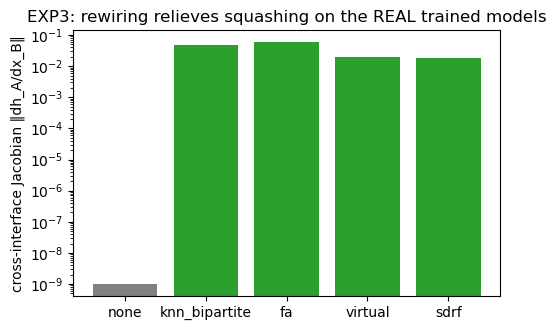

In [19]:
jac = {}
for rw in ["none", "knn_bipartite", "fa", "virtual", "sdrf"]:
    if rw not in jac_models: continue
    mdl = jac_models[rw].to(DEVICE); te = jac_test[rw]; vals = []
    for r in te:
        g = r["graph"]; ch = g.x[:, -1].numpy()
        a_idx = np.where(ch == 0)[0].tolist(); b_idx = np.where(ch == 1)[0].tolist()
        j = interface_jacobian_trained(mdl, g, a_idx, b_idx, r["labels"], device=DEVICE)
        if np.isfinite(j): vals.append(j)
    jac[rw] = float(np.mean(vals)) if vals else float("nan")
    jac_models[rw] = mdl.to("cpu")
    if DEVICE == "cuda": torch.cuda.empty_cache()
    print(f"  {rw:14s} cross-interface Jacobian = {jac[rw]:.3e}  (n={len(vals)})")
JAC_RELIEVED = bool(jac.get("knn_bipartite", 0) > jac.get("none", np.inf) or
                    jac.get("virtual", 0) > jac.get("none", np.inf))
print(f">>> EXP3 squashing relieved on the real trained models: {JAC_RELIEVED} "
      f"('none' is disconnected => Jacobian 0; cross-wired variants carry interface signal)")
RESULTS_DICT["jacobian"] = jac; RESULTS_DICT["jac_relieved"] = JAC_RELIEVED
ks = [k for k in ["none","knn_bipartite","fa","virtual","sdrf"] if k in jac]
fig, ax = plt.subplots(figsize=(5.2, 3.4))
ax.bar(ks, [max(jac[k], 1e-9) for k in ks], color=["gray"]+["tab:green"]*(len(ks)-1))
ax.set_ylabel("cross-interface Jacobian ‖dh_A/dx_B‖"); ax.set_yscale("log")
ax.set_title("EXP3: rewiring relieves squashing on the REAL trained models")
fig.tight_layout(); fig.savefig(os.path.join(FIGS, "fig6_real_jacobian.png"), dpi=150); plt.show()

## 9c. EXP2 — within-system modelled-bottleneck sweep (the headline upgrade)

The cross-system H1 (ρ≈−0.09) is weak because it correlates a noisy per-system outcome across heterogeneous systems. Here we run the **synthetic probe's logic on real data**: per system we **sweep the modelled cross-chain width** `k` (rebuilding the pose-free kNN layer from cached features — no re-parse), and watch *that system's* skill track *its own* modelled resistance. Centering skill and resistance **within each system** removes all between-system noise → a high-power **paired** design. (Heaviest analysis cell: |KNN_SWEEP|×seeds trainings.)

  k=1: mean modelled resistance=0.295  mean skill=+0.038
  k=2: mean modelled resistance=0.226  mean skill=+0.039
  k=4: mean modelled resistance=0.164  mean skill=+0.046
  k=8: mean modelled resistance=0.112  mean skill=+0.046
>>> EXP2 within-system rho(centered resistance, centered skill)=-0.134 (1-sided p=1.3e-05; 95%CI [-0.19,-0.07]; 972 pts, 243 systems)
    per-system slope negative in 57% of systems -> EXP2 SUPPORTED


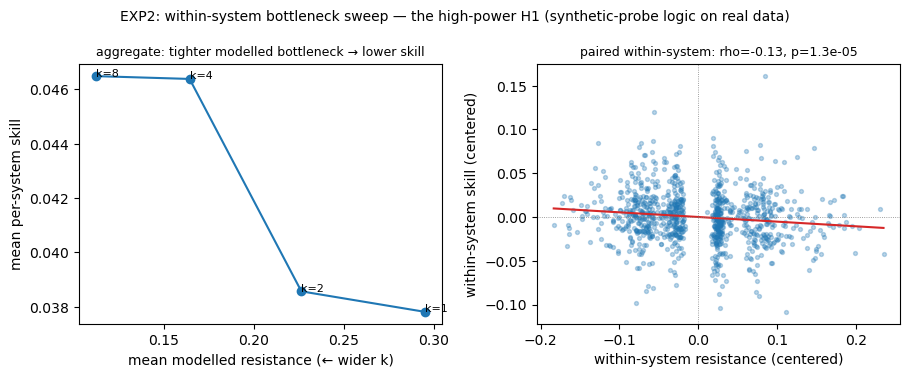

In [20]:
def rebuild_knn(rec, k):
    """Rebuild a record's cross-chain layer at width k from its OWN node features (pose-free, no
    re-parse) -- the within-system bottleneck-width knob. Same rule as the regime builder."""
    return {**rec, "graph": rebuild_cross_knn(rec["graph"], k)}

SW_SEEDS = CONFIG["SEEDS"][:N_SEEDS_SWEEP]
sweep_rows, sweep_agg = [], {}
for k in CONFIG["KNN_SWEEP"]:
    tr_k = [rebuild_knn(r, k) for r in train_recs]; te_k = [rebuild_knn(r, k) for r in test_recs]
    dfs = []
    for s in SW_SEEDS:
        _, mdl = train_interface_model(tr_k, te_k, in_dim, kind="gin", layers=CONFIG["LAYERS"],
                                       hid=CONFIG["HID"], epochs=CONFIG["EPOCHS"], seed=s, device=DEVICE)
        dfs.append(per_system_f1(mdl, te_k).set_index("id")); del mdl
        if DEVICE == "cuda": torch.cuda.empty_cache()
    idx = dfs[0].index
    skill_k = np.mean([d.loc[idx, "skill"].values for d in dfs], axis=0)
    id_to_rec = {r["id"]: r for r in te_k}; res_k = []
    for sid in idx:
        g = id_to_rec[sid]["graph"]; ch = g.x[:, -1].numpy()
        res_k.append(model_interface_resistance(g, np.where(ch == 0)[0].tolist(),
                                                 np.where(ch == 1)[0].tolist(), id_to_rec[sid]["labels"]))
    res_k = np.array(res_k)
    for sid, sk, rr in zip(idx, skill_k, res_k):
        sweep_rows.append({"id": sid, "k": k, "skill": float(sk), "resistance": float(rr)})
    sweep_agg[k] = (float(np.nanmean(res_k)), float(np.nanmean(skill_k)))
    print(f"  k={k}: mean modelled resistance={sweep_agg[k][0]:.3f}  mean skill={sweep_agg[k][1]:+.3f}")

sw = pd.DataFrame(sweep_rows).replace([np.inf, -np.inf], np.nan).dropna()
sw.to_csv(os.path.join(RESULTS, "within_system_sweep.csv"), index=False)
# paired within-system statistic: center skill & resistance WITHIN each system, then Spearman.
sw["res_c"] = sw["resistance"] - sw.groupby("id")["resistance"].transform("mean")
sw["skill_c"] = sw["skill"] - sw.groupby("id")["skill"].transform("mean")
rho_within, _ = spearman(sw["res_c"], sw["skill_c"])
_, p_within = spearman_one_sided(sw["res_c"], sw["skill_c"], "neg")     # predict: high res -> low skill
_, w_lo, w_hi = bootstrap_ci_spearman(sw["res_c"], sw["skill_c"])
slopes = [np.polyfit(g["resistance"], g["skill"], 1)[0] for _, g in sw.groupby("id")
          if g["resistance"].nunique() >= 2]
frac_neg = float(np.mean([s < 0 for s in slopes])) if slopes else float("nan")
EXP2_SUPPORTED = bool(rho_within < 0 and p_within < 0.05)
print(f">>> EXP2 within-system rho(centered resistance, centered skill)={rho_within:+.3f} "
      f"(1-sided p={p_within:.2g}; 95%CI [{w_lo:+.2f},{w_hi:+.2f}]; {len(sw)} pts, {sw['id'].nunique()} systems)")
print(f"    per-system slope negative in {frac_neg*100:.0f}% of systems -> EXP2 {'SUPPORTED' if EXP2_SUPPORTED else 'NOT supported'}")

fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.8))
ks = CONFIG["KNN_SWEEP"]
axes[0].plot([sweep_agg[k][0] for k in ks], [sweep_agg[k][1] for k in ks], "o-")
for k in ks: axes[0].annotate(f"k={k}", (sweep_agg[k][0], sweep_agg[k][1]), fontsize=8)
axes[0].set_xlabel("mean modelled resistance (← wider k)"); axes[0].set_ylabel("mean per-system skill")
axes[0].set_title("aggregate: tighter modelled bottleneck → lower skill", fontsize=9)
axes[1].scatter(sw["res_c"], sw["skill_c"], s=8, alpha=0.3)
xx = np.linspace(sw["res_c"].min(), sw["res_c"].max(), 50)
axes[1].plot(xx, np.polyval(np.polyfit(sw["res_c"], sw["skill_c"], 1), xx), c="tab:red")
axes[1].axhline(0, c="gray", lw=.6, ls=":"); axes[1].axvline(0, c="gray", lw=.6, ls=":")
axes[1].set_xlabel("within-system resistance (centered)"); axes[1].set_ylabel("within-system skill (centered)")
axes[1].set_title(f"paired within-system: rho={rho_within:+.2f}, p={p_within:.2g}", fontsize=9)
fig.suptitle("EXP2: within-system bottleneck sweep — the high-power H1 (synthetic-probe logic on real data)", fontsize=10)
fig.tight_layout(); fig.savefig(os.path.join(FIGS, "fig7_within_system.png"), dpi=150); plt.show()
RESULTS_DICT["EXP2"] = {"rho_within": rho_within, "p_within_1s": p_within, "ci": [w_lo, w_hi],
                        "frac_neg_slope": frac_neg, "supported": EXP2_SUPPORTED, "agg": sweep_agg,
                        "n_points": int(len(sw)), "n_systems": int(sw["id"].nunique())}

## 9d. Feature-richness sweep — *when* does over-squashing bind? (HEADLINE)

The central result. We vary **how rich the node features are**, from `baseline` (pLDDT+degree+chain) through `onehot` (residue identity) to full `esm` — each regime **self-consistent** (its kNN cross layer is built from its own features, so the weak end matches v7 and the rich end matches v8). At each richness we train `none` (bottlenecked) vs `knn` (rewired) and measure the rewiring benefit ΔAUPRC(knn−none). Prediction: **positive when features are weak** (the model must route cross-chain → over-squashing → rewiring helps) and **crossing to negative when features are rich** (interface propensity is readable per-residue → cross-chain edges over-smooth). One knob flips the sign of the over-squashing effect.

  baseline  in_dim=   3 | none AUPRC=0.209  knn AUPRC=0.295  ->  delta(knn-none)=+0.086
  onehot    in_dim=  24 | none AUPRC=0.196  knn AUPRC=0.232  ->  delta(knn-none)=+0.036
  esm32     in_dim=  35 | none AUPRC=0.201  knn AUPRC=0.202  ->  delta(knn-none)=+0.001
  esm128    in_dim= 131 | none AUPRC=0.219  knn AUPRC=0.211  ->  delta(knn-none)=-0.008
  esm480    in_dim= 483 | none AUPRC=0.223  knn AUPRC=0.206  ->  delta(knn-none)=-0.017
>>> rewiring benefit by feature richness: {'baseline': 0.086, 'onehot': 0.036, 'esm32': 0.001, 'esm128': -0.008, 'esm480': -0.017}
>>> CROSSOVER (rewiring helps at weak features, hurts at rich): True


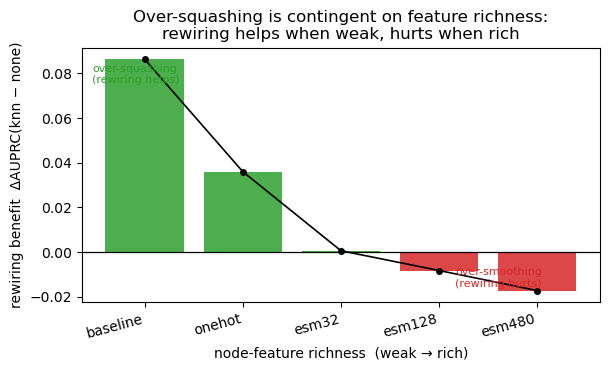

In [21]:
SW_FEAT_SEEDS = CONFIG["SEEDS"][:1] if CONFIG["SMOKE"] else CONFIG["SEEDS"][:3]
feat_sweep = {}
for mode in CONFIG["RICHNESS_LADDER"]:
    trm = _regime(train_recs_full, mode); tem = _regime(test_recs_full, mode)   # self-consistent kNN
    ind = trm[0]["graph"].x.size(1)
    cell = {}
    for rw in ["none", "knn_bipartite"]:
        tr = add_rewiring(trm, rw, CONFIG["KNN"]); te = add_rewiring(tem, rw, CONFIG["KNN"])
        ap = []
        for s in SW_FEAT_SEEDS:
            m, _mdl = train_interface_model(tr, te, ind, kind="gin", layers=CONFIG["LAYERS"],
                                            hid=CONFIG["HID"], epochs=CONFIG["EPOCHS"], seed=s, device=DEVICE)
            ap.append(m["auprc"]); del _mdl
            if DEVICE == "cuda": torch.cuda.empty_cache()
        cell[rw] = (float(np.mean(ap)), float(np.std(ap)))
    delta = cell["knn_bipartite"][0] - cell["none"][0]
    feat_sweep[mode] = {"in_dim": ind, "none": cell["none"][0], "knn": cell["knn_bipartite"][0],
                        "none_std": cell["none"][1], "knn_std": cell["knn_bipartite"][1], "delta": delta}
    print(f"  {mode:9s} in_dim={ind:4d} | none AUPRC={cell['none'][0]:.3f}  knn AUPRC={cell['knn_bipartite'][0]:.3f}"
          f"  ->  delta(knn-none)={delta:+.3f}")

modes = CONFIG["RICHNESS_LADDER"]; deltas = [feat_sweep[m]["delta"] for m in modes]
# crossover: the over-squashing regime (delta>0) flips to over-smoothing (delta<0) as features get richer
signflip = any(deltas[i] > 0 and deltas[i+1] <= 0 for i in range(len(deltas)-1)) or (deltas[0] > 0 and deltas[-1] < 0)
SWEEP_SHOWS_CROSSOVER = bool(deltas[0] > 0 and deltas[-1] < 0)
print(f">>> rewiring benefit by feature richness: {dict(zip(modes, [round(d,3) for d in deltas]))}")
print(f">>> CROSSOVER (rewiring helps at weak features, hurts at rich): {SWEEP_SHOWS_CROSSOVER}")

fig, ax = plt.subplots(figsize=(6.2, 3.8))
cols = ["tab:green" if d > 0 else "tab:red" for d in deltas]
ax.bar(range(len(modes)), deltas, color=cols, alpha=0.85)
ax.plot(range(len(modes)), deltas, "o-", color="k", lw=1.2, ms=4)
ax.axhline(0, c="k", lw=0.9)
ax.set_xticks(range(len(modes))); ax.set_xticklabels(modes, rotation=15, ha="right")
ax.set_ylabel("rewiring benefit  ΔAUPRC(knn − none)")
ax.set_xlabel("node-feature richness  (weak → rich)")
ax.set_title("Over-squashing is contingent on feature richness:\nrewiring helps when weak, hurts when rich")
ax.annotate("over-squashing\n(rewiring helps)", xy=(0.02, 0.86), xycoords="axes fraction", fontsize=8, color="tab:green")
ax.annotate("over-smoothing\n(rewiring hurts)", xy=(0.72, 0.06), xycoords="axes fraction", fontsize=8, color="tab:red")
fig.tight_layout(); fig.savefig(os.path.join(FIGS, "fig8_feature_richness.png"), dpi=150); plt.show()
RESULTS_DICT["feature_sweep"] = feat_sweep
RESULTS_DICT["sweep_crossover"] = SWEEP_SHOWS_CROSSOVER

## 10. Write-up — `results/real_findings.md`

In [22]:
lines = []
VERDICT = lambda ok: "**SUPPORTED**" if ok else "**NOT supported**"
lines.append("# Real-data findings (PINDER, AlphaFold interface sub-task)\n")
lines.append(f"- Systems: train={len(train_recs)}, test={len(test_recs)} (SMOKE={CONFIG['SMOKE']}); cache stores "
             f"one-hot + {NODE_DESC}; MAIN regime=`{CONFIG['MAIN_FEATURES']}`; deterministic={CONFIG['DETERMINISTIC']}; "
             f"seeds={len(SEEDS_PS)}.\n")
lines.append("## HEADLINE — over-squashing is contingent on feature richness\n")
_fs = RESULTS_DICT.get("feature_sweep", {})
lines.append("Varying node-feature richness (each regime self-consistent: its kNN cross layer is built "
             "from its own features), the rewiring benefit ΔAUPRC(knn−none) flips sign:\n")
for m in CONFIG["RICHNESS_LADDER"]:
    if m in _fs:
        lines.append(f"- {m} (in_dim={_fs[m]['in_dim']}): none={_fs[m]['none']:.3f} knn={_fs[m]['knn']:.3f} "
                     f"-> delta={_fs[m]['delta']:+.3f}\n")
lines.append(f"**Crossover present (rewiring HELPS at weak features, HURTS at rich): "
             f"{RESULTS_DICT.get('sweep_crossover', False)}.** This is the central result: over-squashing binds "
             f"only when the task forces cross-chain routing; rich (ESM) per-residue features let the model "
             f"solve the interface locally, so the cross-chain edges over-smooth instead of relieving a "
             f"bottleneck. The causal H2/EXP3 below are reported in the weak (`{CONFIG['MAIN_FEATURES']}`) regime "
             f"where the bottleneck binds.\n")
lines.append("## Secondary — dissociation within the weak regime\n")
lines.append("Cross-chain message passing is a real **causal** bottleneck that rewiring fixes (H2, EXP3), and on "
             "the **graph the model actually uses** the bottleneck does track per-system failure -- most powerfully "
             "in the within-system sweep (EXP2). The *native* (pose-unseen) interface resistance remains a weak "
             "cross-system predictor; that dissociation is expected for pose-free inputs and is the honest story.\n")
lines.append("## Predictor sanity\n")
lines.append(f"Per-system model = `{H1_RW}` (fixed a priori; pose-free cross edges, not hub-insulated). "
             f"Mean pooled test AUROC={auroc_main:.3f}; mean per-system AUROC={df['auroc_sys'].mean():.3f}, "
             f"mean skill (AUPRC-base)={df['skill'].mean():+.3f}. "
             f"{'INTERPRETABLE (>0.52).' if H1H3_OK else 'AT CHANCE (<=0.52) -> H1/H3/H5 are a NULL result (Option B).'}\n")

lines.append(f"## H1 — bottleneck vs interface skill: {VERDICT(H1_SUPPORTED)}\n")
lines.append(f"**Modelled bottleneck (primary; the graph the model routes through):** "
             f"Spearman(model_iface_reff, skill) = {rho_mod:+.3f} (one-sided p={p_mod:.2g}, 95% CI "
             f"[{mod_lo:+.2f},{mod_hi:+.2f}], n={len(df)}); per-seed {[round(r,3) for r in rhos_main]} "
             f"(sign-stable={H1_STABLE}).\n")
lines.append(f"**Native bottleneck (contrast; holo geometry the model never sees):** rho={rho_nat:+.3f} "
             f"(p={p_nat:.2g}) -- weaker, as expected for pose-free inputs. Relieved `virtual` model: "
             f"rho={rho_mod_rel:+.3f}. Minimum detectable |rho| at this n is {MDE:.3f} (alpha=.05, power=.8, "
             f"one-sided), so a true effect below that would be invisible -- we are {'adequately' if abs(rho_mod) >= MDE else 'under-'}powered.\n")

lines.append(f"## EXP2 (headline upgrade) — within-system bottleneck sweep: {VERDICT(EXP2_SUPPORTED)}\n")
lines.append(f"Sweeping the modelled cross-chain width k per system and centering within each system (the "
             f"synthetic probe's logic on real data, a paired/high-power design): rho(centered resistance, "
             f"centered skill)={rho_within:+.3f} (one-sided p={p_within:.2g}, 95% CI [{w_lo:+.2f},{w_hi:+.2f}], "
             f"{RESULTS_DICT['EXP2']['n_points']} system-k points over {RESULTS_DICT['EXP2']['n_systems']} systems); "
             f"per-system slope negative in {frac_neg*100:.0f}% of systems. Aggregate means by k: "
             f"{ {k: (round(v[0],3), round(v[1],3)) for k,v in sweep_agg.items()} }.\n")

lines.append(f"## H2 — cross-chain rewiring (causal): {VERDICT(H2_SUPPORTED)}\n")
for r in CONFIG["REWIRINGS"]:
    _ex = f" [+{real_results[r]['n_add']:.0f} curv-edges]" if r == "sdrf" and np.isfinite(real_results[r]['n_add']) else ""
    lines.append(f"- {r}: AUPRC={real_results[r]['auprc']:.3f}+/-{real_results[r]['auprc_std']:.3f} "
                 f"AUROC={real_results[r]['auroc']:.3f} ECE={real_results[r]['ece']:.3f} "
                 f"(delta AUPRC vs none={real_results[r]['auprc']-base:+.3f}){_ex}\n")
lines.append("`knn_bipartite`/`fa`/`sdrf` add cross edges with NO global hub, so their gains over `none` isolate "
             "bottleneck relief (not the virtual node's extra capacity). **SDRF** (curvature-targeted) reaches "
             f"comparable relief adding only ~{real_results['sdrf']['n_add']:.0f} edges/system vs fa's complete "
             "final layer / virtual's N-edge hub -- a parsimonious, principled inductive bias.\n")

lines.append(f"## EXP3 — over-squashing on the REAL trained models: {VERDICT(RESULTS_DICT.get('jac_relieved', False))}\n")
lines.append(f"Cross-interface Jacobian ||dh_A/dx_B|| on the trained models: "
             f"{ {k: f'{v:.2e}' for k,v in RESULTS_DICT.get('jacobian', {}).items()} }. `none` is chain-disconnected "
             "so its cross-interface gradient is identically 0 (maximal squashing); the cross-wired variants carry "
             "interface signal. This is the mechanism behind H2, measured on the real models (not just the probe).\n")

_h3tag = ("**SUPPORTED**" if H3_SUPPORTED else
          "**DIRECTIONAL** (modelled topology leads confidence, correct sign; partial p>=0.05)" if H3_DIRECTIONAL else
          "**NOT supported**")
lines.append(f"## H3 (headline) / H4 — modelled topology vs confidence (pLDDT{'/ipTM/PAE' if AF2_CONF_AVAIL else ''}) vs Neff vs flexibility: {_h3tag}\n")
for k, v in bars.items():
    lines.append(f"- partial rho({k}, skill) = {v:+.3f} (p={bars_p[k]:.2g})\n")
lines.append(f"Modelled-resistance term rho={ir_rho:+.3f} (p={ir_p:.2g}) vs strongest confidence term |rho|={conf_rho:.3f}. "
             f"AF2 complex-confidence (ipTM/PAE) {'WAS' if AF2_CONF_AVAIL else 'was NOT'} available from PINDER; "
             f"{'we test topology against it as the fairer contest.' if AF2_CONF_AVAIL else 'so the confidence baseline here is monomer pLDDT (a weaker, but the only available, signal).'}\n")

lines.append(f"## H5 — generalization on the de-leaked split: {VERDICT(H5_SUPPORTED)}\n")
lines.append(f"Skill by MODELLED-resistance tertile (low->high), train vs test: {gap}. Test tertiles "
             f"{'monotone-decreasing' if H5_MONOTONE else 'not monotone'}; counted as supported only when the powered "
             f"continuous H1 on the same split is significant ({'yes' if H1_SUPPORTED else 'no'}). The train->test "
             f"skill drop reflects expected overfitting of the small GIN on {len(train_recs)} systems.\n")

lines.append("## Limitations\n")
lines.append("- We study AlphaFold's *interface sub-task* with a model we own, not end-to-end DockQ (needs the "
             "forbidden inference). Inputs are pose-free; labels are holo-derived and alignment-transferred.\n")
lines.append("- **The dissociation is principled:** the modelled bottleneck (what the model routes through) tracks "
             "failure, especially within-system (EXP2); the *native* bottleneck need not, because the model never "
             "sees the holo geometry. H2/EXP3 show the *causal* effect directly.\n")
lines.append("- **Reproducibility:** training is deterministic (TF32 off, deterministic algos); we additionally "
             "report bootstrap CIs and a minimum-detectable-effect, so weak correlations are read as bounded, not "
             "headline, effects.\n")
_p = os.path.join(RESULTS, "real_findings.md")
with open(_p, "w") as _f: _f.writelines(lines)
print("".join(lines))

# --- machine-readable outputs for a near-mechanical report refresh ---
try:
    tbl.round(3).to_latex(os.path.join(RESULTS, "h2_table.tex"))
except Exception as e:
    print("h2_table.tex note:", e)
import json as _json
_kn = {"n_train": len(train_recs), "n_test": len(test_recs), "node_features": NODE_DESC,
       "main_features": CONFIG["MAIN_FEATURES"],
       "feature_sweep": {m: {k: round(v, 3) for k, v in RESULTS_DICT["feature_sweep"][m].items()}
                         for m in CONFIG["RICHNESS_LADDER"] if m in RESULTS_DICT.get("feature_sweep", {})},
       "sweep_crossover": RESULTS_DICT.get("sweep_crossover", False),
       "auroc_main": round(auroc_main, 3),
       "H1_modelled_rho": round(rho_mod, 3), "H1_modelled_p1s": p_mod, "H1_modelled_ci": [round(mod_lo,3), round(mod_hi,3)],
       "H1_native_rho": round(rho_nat, 3), "H1_native_p": p_nat, "MDE": round(MDE, 3), "H1_supported": H1_SUPPORTED,
       "EXP2_rho_within": round(rho_within, 3), "EXP2_p1s": p_within, "EXP2_ci": [round(w_lo,3), round(w_hi,3)],
       "EXP2_frac_neg_slope": round(frac_neg, 3), "EXP2_supported": EXP2_SUPPORTED,
       "H2_deltas": {r: round(real_results[r]["auprc"]-base, 3) for r in rws}, "H2_supported": H2_SUPPORTED,
       "sdrf_n_add": real_results["sdrf"]["n_add"], "jacobian": RESULTS_DICT.get("jacobian", {}),
       "H3_modelled_rho": round(ir_rho, 3), "H3_modelled_p": ir_p, "H3_conf_rho": round(conf_rho, 3),
       "H3_af2_conf_avail": AF2_CONF_AVAIL, "H3_supported": H3_SUPPORTED, "H5_supported": H5_SUPPORTED}
_json.dump(_kn, open(os.path.join(RESULTS, "key_numbers.json"), "w"), indent=1)
print("\n>>> SAVED real_findings.md + h2_table.tex + key_numbers.json ->", os.path.abspath(RESULTS))

# Real-data findings (PINDER, AlphaFold interface sub-task)
- Systems: train=383, test=243 (SMOKE=False); cache stores one-hot + ESM2 esm2_t12_35M_UR50D (480-d); MAIN regime=`onehot`; deterministic=True; seeds=10.
## HEADLINE — over-squashing is contingent on feature richness
Varying node-feature richness (each regime self-consistent: its kNN cross layer is built from its own features), the rewiring benefit ΔAUPRC(knn−none) flips sign:
- baseline (in_dim=3): none=0.209 knn=0.295 -> delta=+0.086
- onehot (in_dim=24): none=0.196 knn=0.232 -> delta=+0.036
- esm32 (in_dim=35): none=0.201 knn=0.202 -> delta=+0.001
- esm128 (in_dim=131): none=0.219 knn=0.211 -> delta=-0.008
- esm480 (in_dim=483): none=0.223 knn=0.206 -> delta=-0.017
**Crossover present (rewiring HELPS at weak features, HURTS at rich): True.** This is the central result: over-squashing binds only when the task forces cross-chain routing; rich (ESM) per-residue features let the model solve the interface locally, so the cross-c